# Mapping ten grid algorithms with and without their names (TP-G, iteration 9): demo

**Question.** Asked to write a grid path-search function, Qwen3-32B nearly always writes BFS. When the five algorithms
it writes most often (**BFS, DFS, IDDFS, A\*, greedy best-first search**) are banned in the prompt, the programs that
still solve the task are mostly **unit-weight Dijkstra** (15 survivors in iteration 8). Where does that survivor sit
in the model's internal map of the ten algorithms: at the **EDGE** of the banned five, or on the **OPPOSITE** side?
And does that map encode what the algorithms *do*, or only their *names*?

**Method.** The artifact rebuilds the ten-algorithm manifold from Qwen3-32B residual-stream activations in four ways,
holding the model, readout, block rule, k and landing code fixed:

| Manifold | Stimuli | Algorithm names in the stimulus? |
|---|---|---|
| **M-name** | 300 prompts that name each algorithm (10 templates x 3 aliases) | yes |
| M-desc | name-free mechanism descriptions that Qwen3-32B can still name | no |
| M-lex | alias sentence minus a token-matched neutral-noun twin | only the name |
| **M-code** | name-scrubbed, verified programs, teacher-forced through the model | no |

On each manifold the code builds a symmetrised kNN graph on the activations and takes shortest-path (geodesic)
distances. For every non-banned algorithm it computes
**g(a) = min over banned b of the mean geodesic distance between a's points and b's points**.
An algorithm with g below the median of the non-banned algorithms is **EDGE**; one above the median is **OPPOSITE**.
A landing test then asks whether the 15 unit-Dijkstra survivors sit closer (EDGE) or farther (OPPOSITE) than random
draws of non-banned labels.

**Full-run result (pre-registered named outcome: MIXED).** Unit Dijkstra is OPPOSITE on the manifolds built from
names and descriptions (M-name: rank 5 of 5, g/median 1.63) but at the EDGE on the code manifold (M-code: rank 1 of 2,
g/median 0.67). The geometry is correlational: it shows where representations sit, not whether the model uses
this geometry to choose an algorithm.

**What this notebook runs.** The artifact's own analysis code (`geometry.py`, `landing.py`, `stage_analysis.py`,
`stage_outputs.py`, `stage_figures.py`), copied into cells, with notebook-only changes marked `# notebook:`. It runs
on **98 real cached Qwen3-32B activation vectors** loaded from `mini_demo_data.json`: 50 M-name prompts
(block 31, 5 per algorithm) and 48 M-code programs (block 33, 8 per algorithm).

**What it does not run.** These steps need the model weights, a GPU, the OpenRouter API or the 1.3 GB state cache
(which stays on the run volume): state extraction, the naming gate and program top-ups, sandboxed acceptance and
scrubbing of programs, and block selection across 27 blocks. The notebook prints the full-run numbers beside its own.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru - NOT pre-installed on Colab, always install (the artifact's modules log through loguru)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib - pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# Original import blocks of geometry.py, landing.py, stage_analysis.py, stage_outputs.py and stage_figures.py
import collections
import itertools
import json
import multiprocessing as mp  # noqa: F401  (original; the notebook's _pool() uses threads, see below)
import os
import sys
from collections import Counter
from concurrent.futures import ProcessPoolExecutor  # noqa: F401  (original)
from pathlib import Path
from typing import Any

import matplotlib  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np
from loguru import logger
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform  # noqa: F401
from scipy.stats import mannwhitneyu, rankdata, spearmanr

# notebook additions
import time
import types
from concurrent.futures import ThreadPoolExecutor

# notebook: stage_figures.py called matplotlib.use("Agg") (files only); the notebook keeps the inline backend.
# common.setup_logging(): INFO lines to stdout (the original also kept a rotating log file under logs/).
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
_T_START = time.time()

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-9/experiment-46/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

EXAMPLES = data["datasets"][0]["examples"]
print(f"{len(EXAMPLES)} points from the '{data['datasets'][0]['dataset']}' dataset; "
      f"hidden size {data['metadata']['hidden_size']}")
for _name, _info in data["metadata"]["manifolds"].items():
    _n = Counter(e["output"] for e in EXAMPLES if e["metadata_manifold"] == _name)
    print(f"  {_name}: block {_info['block']}, {sum(_n.values())} of the full run's {_info['n_full']} points, "
          f"per algorithm {dict(_n)}")
print("\nM-name prompt (alias 'breadth-first search (BFS)', template 0):\n" + EXAMPLES[0]["input"][:420] + " ...")
_ex = next(e for e in EXAMPLES if e["metadata_manifold"] == "mcode_PRIMARY_R1" and e["output"] == "dijkstra_unit")
print(f"\nM-code program (name-scrubbed; label {_ex['output']}; {_ex['metadata_author']}):\n" + _ex["input"][:700])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
98 points from the 'tpg_points' dataset; hidden size 5120
  mname: block 31, 50 of the full run's 300 points, per algorithm {'bfs': 5, 'dfs': 5, 'bibfs': 5, 'iddfs': 5, 'astar': 5, 'gbfs': 5, 'dijkstra_unit': 5, 'idastar': 5, 'jps': 5, 'biastar': 5}
  mcode_PRIMARY_R1: block 33, 48 of the full run's 117 points, per algorithm {'bfs': 8, 'dfs': 8, 'astar': 8, 'gbfs': 8, 'dijkstra_unit': 8, 'idastar': 8}

M-name prompt (alias 'breadth-first search (BFS)', template 0):
Implement breadth-first search (BFS) for this task.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours  ...

M-code program (name

## Configuration

Every tunable value sits in the next cell. Two kinds:

* **Demo scale.** How many points per algorithm to take from each manifold of `mini_demo_data.json`. Smaller
  numbers are faster but noisier. The demo data holds at most 5 per algorithm for M-name and 8 for M-code.
  The full run used 30 and 17-20, which needs the full state cache.
* **Frozen settings of the artifact** (`tpg.py`) and null sizes. The kNN sizes `KS = (5, 10, 15)` with verdict
  k = 15 and second setting k = 10 were pre-registered; the bootstrap and null sizes are the original values unless
  a comment says otherwise.

In [5]:
# ---------------------------------------------------------------------------------------------- demo scale
# Points per algorithm taken from each manifold of mini_demo_data.json (the first N in stored order, so every N keeps
# the same paraphrase groups / program ranks for all algorithms). Maximum in the demo data: 5 (M-name), 8 (M-code).
# Full run (original): 30 per algorithm on M-name (300 points) and 17-20 per algorithm on M-code (117 programs); that
# needs the full state cache (cache/states/, about 1.3 GB, kept on the run volume and not published).
# Smallest values that run: 2 and 3 (sklearn's Isomap needs more than K_VERDICT = 15 points per manifold).
N_PER_CLASS_MNAME = 5                # all M-name points in the demo data
N_PER_CLASS_MCODE = 8                # all M-code points in the demo data

# ---------------------------------------------------------------------------------------------- frozen settings (tpg.py)
KS = (5, 10, 15)
K_VERDICT = 15                       # iteration 8's primary k (k 10 is the committed second verdict setting)
K_SECOND = 10
N_BOOT_32B = 1000                    # bootstrap resamples on the Qwen3-32B verdict manifolds (original: 1000)
N_BOOT_OTHER = 200                   # bootstrap resamples on the other manifolds (original: 200)

# ---------------------------------------------------------------------------------------------- null sizes
LANDING_DRAWS = 10000                # iid null draws in landing.landing / iid_null (original: 10000)
PERM_N = 100000                      # random permutations in stage_analysis._perm_p (original: 100000)
N_WORKERS = 2                        # pool size (original TPG_WORKERS default: 12 processes; threads here)

## Frozen catalogue, banned split and gates (`common.py`, `tpg.py`)

The ten algorithms are always handled in one canonical order. The **banned five** (B5) are iteration 8's top five
for configuration C6, the prompt that produced the 15 unit-Dijkstra survivors. The other five (NB5) are the
candidates that can land at the EDGE or OPPOSITE. Gates and model pins were hash-committed before any state was
extracted (`commitments.log` in the artifact).

`method.py` is a stage orchestrator. In run order:
`inputs` → `commit0` → `mname` (GPU) → `cpu` → `naming` / `topups` (OpenRouter) → `pools` → `states` (GPU) →
`blocks` → **`analyse`** → **`figures`** → **`outputs`**. This notebook reproduces the **bold** stages on the demo
subset. The upstream stages produced the activation vectors and auxiliary inputs stored in `mini_demo_data.json`.

In [6]:
# ---------------------------------------------------------------------------------------------- common.py
CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "BiBFS", "iddfs": "IDDFS", "astar": "A*", "gbfs": "GBFS",
         "dijkstra_unit": "Dijkstra(u)", "idastar": "IDA*", "jps": "JPS", "biastar": "BiA*", "other": "other",
         "no_code": "no code", "invalid": "invalid"}

# ---------------------------------------------------------------------------------------------- tpg.py: catalogue split
B5 = ["bfs", "dfs", "iddfs", "astar", "gbfs"]                       # banned (iteration-8 C6 top five)
NB5 = ["bibfs", "biastar", "idastar", "jps", "dijkstra_unit"]       # non-banned
UDIJ = "dijkstra_unit"
assert set(B5) | set(NB5) == set(CANON_ORDER)

# ---------------------------------------------------------------------------------------------- tpg.py: models
M32 = {"repo": "unsloth/Qwen3-32B-bnb-4bit", "revision": "7f721e74a6a8cc9ee352f7e49303a2c1705f9083",
       "precision": "nf4", "n_layers": 64, "n_keep": 48, "ext_blocks": list(range(17, 48)),
       "sel_blocks": list(range(19, 46)), "tag": "32b", "engine": "hf-nf4-truncated", "ref_block": 31}
MODELS = {"32b": M32}   # notebook: the Qwen3-8B entry is omitted (the demo subset holds Qwen3-32B states only)

# ---------------------------------------------------------------------------------------------- tpg.py: frozen settings
MCODE_MIN = 10
LOO_GATE = 0.70
RELIABILITY_FLAG = 0.70
SEED = 9009

# Survivors of iteration 8 (C6, Qwen3-32B thinking on): label-level landing input (landing.json / confirmation.json).
SURV_SCREEN = [UDIJ] * 6
SURV_CONFIRM = [UDIJ] * 9

# ---------------------------------------------------------------------------------------------- stage_analysis.py
VERDICT_MANIFOLDS = ["mname", "mdesc", "mlex", "mcode_PRIMARY_R1", "mcode_PRIMARY_R2", "mcode_M32_R1", "mcode_M8_R1"]

# notebook: the original wrote cache/states/, results/ and figures/ inside the artifact folder; the notebook writes
# the same files under ./tpg_demo_outputs/
ROOT = Path("tpg_demo_outputs")
STATES_DIR = ROOT / "cache" / "states"
RESULTS = ROOT / "results"
for _d in (STATES_DIR, RESULTS, ROOT / "figures" / "coords"):
    _d.mkdir(parents=True, exist_ok=True)


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + f".tmp{os.getpid()}")
    tmp.write_text(json.dumps(obj, indent=indent, ensure_ascii=False, default=_json_default))
    tmp.replace(p)

## Geometry primitives (`geometry.py`, iteration 8's module, unchanged)

All geometry runs in raw activation coordinates (5,120-dimensional residual states of Qwen3-32B):

* `knn_graph`: Euclidean distances, keep each point's k nearest neighbours, symmetrise. If the graph falls apart,
  join the components by their shortest inter-component edges, as sklearn's Isomap does.
* `geodesics`: all-pairs shortest paths (Dijkstra) on that graph, i.e. distances measured *along* the manifold.
* `class_matrix`: 10 x 10 matrix of mean geodesic distances between the points of two algorithms.
* `g_values`: for each non-banned algorithm, g = distance to its *nearest* banned algorithm.
* `classify`: EDGE if g < median of the non-banned g values, OPPOSITE if g > median, MIDDLE if equal.
* `g_centroid`: the same g on plain Euclidean centroid distances (a sensitivity check).
* `classical_mds` and `stress1`: 2-D embeddings for the figures, with Kruskal stress-1 as the distortion measure.

In [7]:
# ---------------------------------------------------------------------------------------------- graphs
def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def class_matrix(geo: np.ndarray, labels: np.ndarray, classes: list[str]) -> np.ndarray:
    M = np.zeros((len(classes), len(classes)))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            sub = geo[np.ix_(labels == a, labels == b)]
            if i == j:
                sub = sub[~np.eye(len(sub), dtype=bool)] if sub.shape[0] == sub.shape[1] else sub
            M[i, j] = float(np.mean(sub)) if sub.size else np.nan
    return M


def g_values(geo: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.mean(geo[np.ix_(labels == a, labels == b)])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def g_centroid(X: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    cent = {c: X[labels == c].mean(0) for c in set(labels)}
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.linalg.norm(cent[a] - cent[b])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def classify(g: dict[str, float]) -> tuple[dict[str, str], float]:
    med = float(np.median(list(g.values())))
    cls = {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}
    return cls, med


# ---------------------------------------------------------------------------------------------- embeddings
def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))

## Landing test (`landing.py`, iteration 8's module)

The statistic is **S = mean g over the survivors' labels**: here the 15 unit-Dijkstra survivors (6 from the screen,
9 from the confirmation run). S is compared with four nulls that redraw the survivors' labels among the non-banned
algorithms:

* **U**: uniform draws.
* **F**: draws weighted by the C6 baseline frequency (+0.5 smoothing).
* **P**: all 120 permutations of algorithm identities, with the count profile fixed.
* **C**: draws weighted by the correct-when-forced rates (the correctness-filter confound).

`p_edge = P(S_null <= S)` and `p_opp = P(S_null >= S)`.
**Verdict:** EDGE if p_edge(U) < 0.05, p_edge(F) < 0.05 and more than half of the survivors are in EDGE algorithms.
OPPOSITE is the mirror image. Anything else is NEITHER.

In [8]:
def stat(g: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([g[a] for a in labels])) if labels else float("nan")


# notebook: draws default is LANDING_DRAWS from the config cell (original: 10000)
def iid_null(g: dict[str, float], probs: dict[str, float], n: int, draws: int = LANDING_DRAWS,
             seed: int = 0) -> np.ndarray:
    algs = list(g)
    p = np.array([probs[a] for a in algs], dtype=float)
    p = p / p.sum()
    vals = np.array([g[a] for a in algs])
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(algs), size=(draws, n), p=p)
    return vals[idx].mean(1)


def perm_null(g: dict[str, float], labels: list[str]) -> np.ndarray:
    algs = list(g)
    cnt = collections.Counter(labels)
    counts = np.array([cnt[a] for a in algs], dtype=float)
    vals = np.array([g[a] for a in algs])
    out = []
    for perm in itertools.permutations(range(len(algs))):
        out.append(float((counts * vals[list(perm)]).sum() / counts.sum()))
    return np.array(out)


def pvals(null: np.ndarray, S: float) -> dict[str, float]:
    eps = 1e-12
    return {"p_edge": float(np.mean(null <= S + eps)), "p_opp": float(np.mean(null >= S - eps)),
            "null_mean": float(null.mean()), "null_q": np.quantile(null, [0.025, 0.05, 0.5, 0.95, 0.975]).tolist(),
            "n": int(len(null))}


def landing(g: dict[str, float], classes: dict[str, str], surv: list[str], base_counts: dict[str, int],
            forced_rates: dict[str, float], draws: int = LANDING_DRAWS, seed: int = 0) -> dict[str, Any]:
    nonbanned = list(g)
    n = len(surv)
    out: dict[str, Any] = {"n_surv": n, "survivor_counts": dict(collections.Counter(surv)), "g": g, "classes": classes}
    if n == 0:
        out.update({"S": None, "verdict": "NO SURVIVORS", "descriptive_only": True})
        return out
    S = stat(g, surv)
    out["S"] = S
    U = iid_null(g, {a: 1.0 for a in nonbanned}, n, draws, seed)
    fprobs = {a: base_counts.get(a, 0) + 0.5 for a in nonbanned}
    F = iid_null(g, fprobs, n, draws, seed + 1)
    P = perm_null(g, surv)
    cprobs = {a: forced_rates.get(a, 0.0) + 0.5 / 40 for a in nonbanned}
    C = iid_null(g, cprobs, n, draws, seed + 2)
    out["nulls"] = {"U": pvals(U, S), "F": pvals(F, S), "P": pvals(P, S), "C": pvals(C, S)}
    out["null_F_probs"] = fprobs
    out["null_F_near_uniform"] = all(base_counts.get(a, 0) == 0 for a in nonbanned)
    out["null_C_probs"] = cprobs
    share = collections.Counter(classes[a] for a in surv)
    out["class_shares"] = {k: v / n for k, v in share.items()}
    pU, pF = out["nulls"]["U"], out["nulls"]["F"]
    if pU["p_edge"] < 0.05 and pF["p_edge"] < 0.05 and share["EDGE"] / n > 0.5:
        v = "EDGE"
    elif pU["p_opp"] < 0.05 and pF["p_opp"] < 0.05 and share["OPPOSITE"] / n > 0.5:
        v = "OPPOSITE"
    else:
        v = "NEITHER"
    out["verdict"] = v
    out["descriptive_only"] = n < 5
    out["perm_floor"] = float(1.0 / len(P) * sum(1 for x in P if abs(x - P.min()) < 1e-12))
    out["_nulls_raw"] = {"U": U, "F": F, "P": P, "C": C}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}

### Module-name shim (notebook only)

The stage code below was written against modules. It calls `geometry.geodesics(...)` and `landing.landing(...)`,
and its worker functions run `import geometry as gm`, `from tpg import B5` and `__import__("common")`. The next cell
registers the functions defined above under those module names, so the copied stage code runs without edits.

In [9]:
def _as_module(name: str, **attrs: Any) -> types.ModuleType:
    mod = types.ModuleType(name)
    mod.__dict__.update(attrs)
    sys.modules[name] = mod
    return mod


geometry = _as_module("geometry", knn_graph=knn_graph, geodesics=geodesics, class_matrix=class_matrix,
                      g_values=g_values, g_centroid=g_centroid, classify=classify, stress1=stress1,
                      classical_mds=classical_mds, squareform=squareform, pdist=pdist, cdist=cdist)
_landing_fn = landing.landing if isinstance(landing, types.ModuleType) else landing   # re-running this cell is safe
landing = _as_module("landing", stat=stat, iid_null=iid_null, perm_null=perm_null, pvals=pvals, landing=_landing_fn,
                     strip=strip)
_as_module("tpg", B5=B5, NB5=NB5, UDIJ=UDIJ, KS=KS, K_VERDICT=K_VERDICT, K_SECOND=K_SECOND)
_as_module("common", CANON_ORDER=CANON_ORDER, SHORT=SHORT)
print("registered:", [m for m in ("geometry", "landing", "tpg", "common") if m in sys.modules])

registered: ['geometry', 'landing', 'tpg', 'common']


## Loading a manifold (`stage_analysis.load_manifold`)

In the artifact, `load_manifold` reads `cache/states/<manifold>_<model>.npz`: float16 states of shape
`[n, 31 blocks, 5120]`, plus each point's algorithm label, its paraphrase group and its id. The notebook version builds
the same dictionary from `mini_demo_data.json`. The stored decimals are parsed as float16, which recovers the cached
values exactly, then cast to float32 as the original did. Only the selected block L\* is in the demo data, so
`blocks` has a single entry. L\* was chosen in the full run by the label-only layer rule over 27 blocks (stage 6):
block 31 for M-name and block 33 for M-code.

* **M-name** points: 5 of the 30 paraphrase groups per algorithm, the same groups for every algorithm
  (group = 3 x template + alias). The first N in stored order cover all three aliases once N >= 3.
* **M-code** points: 8 programs per algorithm for the six algorithms that have at least `MCODE_MIN = 10` verified
  programs in the full PRIMARY set (BiBFS, IDDFS, JPS and BiA* have fewer, so they are excluded exactly as in the
  full run). Group = rank % 10; the subset mixes Qwen3-8B and Qwen3-32B programs.

In [10]:
def load_manifold(model_tag: str, name: str) -> dict[str, Any] | None:
    """X [n, n_blocks, d] float32, labels, groups, ids, blocks, stimulus info.

    notebook: built from mini_demo_data.json (one block, L*) instead of cache/states/<name>_<model>.npz; the first
    N_PER_CLASS_* points of every algorithm are used."""
    rows = [e for e in EXAMPLES if e["metadata_manifold"] == name and e["metadata_model"] == MODELS[model_tag]["repo"]]
    if not rows:
        return None
    if name.startswith("mcode_"):
        # MCODE_MIN applies to the size of the full program set, as in the original (len(prog) < MCODE_MIN -> skip)
        full_counts = data["metadata"]["manifolds"][name]["program_counts_full_set"]
        rows = [e for e in rows if full_counts[e["output"]] >= MCODE_MIN]
    n_per = N_PER_CLASS_MNAME if name == "mname" else N_PER_CLASS_MCODE
    taken: Counter = Counter()
    sel = []
    for e in rows:
        if taken[e["output"]] < n_per:
            sel.append(e)
            taken[e["output"]] += 1
    X = np.stack([np.array(e["activation"], dtype=np.float16) for e in sel]).astype(np.float32)[:, None, :]
    out = {"X": X, "labels": np.array([e["output"] for e in sel]),
           "groups": np.array([e["metadata_group"] for e in sel]).astype(int),
           "ids": np.array([e["metadata_point_id"] for e in sel]), "blocks": [int(sel[0]["metadata_block"])]}
    if name == "mname":
        out["template"] = np.array([e["metadata_template"] for e in sel])
        out["alias"] = np.array([e["metadata_alias_index"] for e in sel])
    if name.startswith("mcode_"):
        _, frame, ro = name.split("_")
        out.update({"readout": ro, "frame": frame, "keys": out["ids"]})
    return out


for _name in ("mname", "mcode_PRIMARY_R1"):
    _m = load_manifold("32b", _name)
    print(f"{_name}: X {_m['X'].shape} {_m['X'].dtype}, block {_m['blocks']}, groups {sorted(set(_m['groups'].tolist()))}, "
          f"classes {dict(Counter(_m['labels'].tolist()))}")

mname: X (50, 1, 5120) float32, block [31], groups [0, 7, 14, 21, 28], classes {'bfs': 5, 'dfs': 5, 'bibfs': 5, 'iddfs': 5, 'astar': 5, 'gbfs': 5, 'dijkstra_unit': 5, 'idastar': 5, 'jps': 5, 'biastar': 5}
mcode_PRIMARY_R1: X (48, 1, 5120) float32, block [33], groups [0, 1, 2, 3, 4, 5, 6, 7], classes {'bfs': 8, 'dfs': 8, 'astar': 8, 'gbfs': 8, 'dijkstra_unit': 8, 'idastar': 8}


## Describing one manifold (`stage_analysis.describe`)

`describe` is the core measurement at one block:

1. PCA (explained-variance ratios), plus classical MDS of all points and of the class centroids, each with stress-1.
2. For each k in `KS`: geodesics on the kNN graph, then **g / nearest banned / class** of every non-banned algorithm
   present, the 10 x 10 class-geodesic matrix (the "neural RDM" used later by RSA), and unit Dijkstra's **rank**
   (1 = nearest to the banned five) and **g / median ratio** (< 1 means EDGE, > 1 means OPPOSITE).
3. The same g on Euclidean centroid distances, with no graph.
4. Optionally an Isomap embedding at the verdict k, used by the figures.

The median rule is relative. With only two non-banned algorithms present (M-code keeps IDA* and unit Dijkstra),
one is necessarily EDGE and the other OPPOSITE. The artifact reports such classes but flags them as weaker than
classes over all five non-banned algorithms (M-name).

In [11]:
def classes_of(g: dict[str, float]) -> tuple[dict[str, str], float]:
    return geometry.classify(g)


def describe(X: np.ndarray, labels: np.ndarray, ks: tuple[int, ...] = KS, embed: bool = False) -> dict[str, Any]:
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    nb = [a for a in NB5 if a in present]
    bp = [b for b in B5 if b in present]
    out: dict[str, Any] = {"n_points": int(len(X)), "present": present, "nonbanned_used": nb, "banned_used": bp}
    from sklearn.decomposition import PCA

    pca = PCA(n_components=min(10, len(X) - 1), random_state=0).fit(X)
    out["pca_evr"] = pca.explained_variance_ratio_.tolist()
    D = geometry.squareform(geometry.pdist(X))
    Ym = geometry.classical_mds(D)
    out["mds_points_stress1"] = geometry.stress1(D, Ym)
    cent = np.stack([X[labels == c].mean(0) for c in present])
    Dc = geometry.squareform(geometry.pdist(cent))
    Ymc = geometry.classical_mds(Dc)
    out["mds_centroids_stress1"] = geometry.stress1(Dc, Ymc)
    out["centroid_distance_matrix"] = Dc.tolist()
    emb = {"pca": pca, "mds_points": Ym, "mds_centroids": Ymc, "geo": {}, "D": D}
    for k in ks:
        geo, info = geometry.geodesics(X, k)
        g, near = geometry.g_values(geo, labels, bp, nb)
        cls, med = classes_of(g)
        M = geometry.class_matrix(geo, labels, CANON_ORDER)
        rank = sorted(nb, key=lambda a: g[a]).index(UDIJ) + 1 if UDIJ in nb else None
        out[f"k{k}"] = {**info, "g": g, "nearest_banned": near, "classes": cls, "median": med,
                        "class_geodesic_matrix": M.tolist(), "udij_rank": rank,
                        "udij_ratio": (g[UDIJ] / med) if UDIJ in nb and med > 0 else None}
        emb["geo"][k] = geo
    gc_, nc_ = geometry.g_centroid(X, labels, bp, nb)
    clc, medc = classes_of(gc_)
    out["euclid_centroid"] = {"g": gc_, "nearest_banned": nc_, "classes": clc, "median": medc}
    if embed:
        from sklearn.manifold import Isomap

        iso = Isomap(n_neighbors=K_VERDICT, n_components=2).fit(X)
        emb["isomap"] = (iso, iso.embedding_)
    out["_emb"] = emb
    return out

## Reliability, sensitivity and landing (`stage_analysis.py`)

* `split_half`: split the paraphrase groups at their median. Compare the two halves' class-geodesic matrices
  (Spearman), apply the Spearman–Brown correction, and report a noise ceiling for RSA.
* `bootstrap`: resample whole paraphrase groups with replacement (duplicates are kept, with a 1e-9 jitter) and
  recompute g. Gives class stability, P(EDGE), a 95% CI of unit Dijkstra's g/median, and the bootstrap matrices
  that RSA uses for CIs of rho differences.
* `crossnobis`: cross-validated squared centroid distances between the two halves, a distance with no kNN graph.
* `landing_all`: the landing test for the screen (6), confirmation (9) and pooled (15) survivors. Inputs are
  iteration 8's C6 baseline labels (91 BFS, 9 invalid, so null F is near uniform) and the correct-when-forced rates.
* `robustness`: re-runs classes and verdicts over blocks L\*-2..L\*+2 and all k. The demo data has L\* only, so the
  grid shrinks to the three k cells at L\*. The full run has 15 cells.

**notebook:** `_pool()` uses a thread pool. Spawned worker processes cannot import functions defined in a notebook.

In [12]:
def _pool() -> ThreadPoolExecutor:
    # notebook: original ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=mp.get_context("spawn"),
    # initializer=_init_worker); spawned processes cannot import functions defined in notebook cells.
    return ThreadPoolExecutor(max_workers=N_WORKERS)


def split_half(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int) -> dict[str, Any]:
    ug = np.unique(groups)
    thr = ug[len(ug) // 2]
    h1 = groups < thr
    mats = []
    for m in (h1, ~h1):
        geo, _ = geometry.geodesics(X[m], k)
        M = geometry.class_matrix(geo, labels[m], CANON_ORDER)
        mats.append((M + M.T) / 2)
    present = [i for i, a in enumerate(CANON_ORDER) if a in set(labels.tolist())]
    iu = [(i, j) for i, j in itertools.combinations(present, 2)]
    a = [mats[0][i, j] for i, j in iu]
    b = [mats[1][i, j] for i, j in iu]
    rho = float(spearmanr(a, b).statistic)
    sb = 2 * rho / (1 + rho) if rho > -1 else float("nan")
    return {"k": k, "split_threshold_group": int(thr), "spearman_halves": rho, "spearman_brown": sb,
            "noise_ceiling_upper": float(np.sqrt(max(sb, 0.0))), "flag_unreliable": sb < RELIABILITY_FLAG,
            "half_matrices": [m.tolist() for m in mats]}


def _boot_chunk(args: tuple) -> list[dict[str, Any]]:
    X, labels, groups, k, seeds = args
    import geometry as gm
    from tpg import B5 as b5, NB5 as nb5

    nb = [a for a in nb5 if a in set(labels.tolist())]
    b5 = [b for b in b5 if b in set(labels.tolist())]
    ug = np.unique(groups)
    out = []
    for s in seeds:
        rng = np.random.default_rng(s)
        gs = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in gs])
        Xb = X[idx] + rng.normal(0, 1e-9, size=X[idx].shape)
        geo, _ = gm.geodesics(Xb, k)
        g, near = gm.g_values(geo, labels[idx], b5, nb)
        M = gm.class_matrix(geo, labels[idx], list(__import__("common").CANON_ORDER))
        out.append({"g": g, "near": near, "M": ((M + M.T) / 2).tolist()})
    return out


def bootstrap(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int, n_boot: int, full: dict[str, Any],
              seed: int = 0) -> dict[str, Any]:
    seeds = [seed * 100000 + i for i in range(n_boot)]
    chunks = [seeds[i::N_WORKERS] for i in range(N_WORKERS)]
    with _pool() as ex:
        res = [r for part in ex.map(_boot_chunk, [(X, labels, groups, k, c) for c in chunks if c]) for r in part]
    nb = list(full["g"].keys())
    full_cls = full["classes"]
    cls_runs = [classes_of(r["g"])[0] for r in res]
    ratios = [r["g"][UDIJ] / float(np.median(list(r["g"].values()))) for r in res] if UDIJ in nb else []
    ranks = [sorted(nb, key=lambda a: r["g"][a]).index(UDIJ) + 1 for r in res] if UDIJ in nb else []
    return {"n_boot": len(res), "k": k,
            "class_stability": {a: float(np.mean([c[a] == full_cls[a] for c in cls_runs])) for a in nb},
            "edge_probability": {a: float(np.mean([c[a] == "EDGE" for c in cls_runs])) for a in nb},
            "opposite_probability": {a: float(np.mean([c[a] == "OPPOSITE" for c in cls_runs])) for a in nb},
            "nearest_banned_stability": {a: float(np.mean([r["near"][a] == full["nearest_banned"][a] for r in res]))
                                         for a in nb},
            "udij_ratio_ci95": [float(np.quantile(ratios, 0.025)), float(np.quantile(ratios, 0.975))] if ratios
            else None, "udij_rank_distribution": {int(v): ranks.count(v) for v in sorted(set(ranks))},
            "_matrices": [r["M"] for r in res]}


def crossnobis(X: np.ndarray, labels: np.ndarray, groups: np.ndarray) -> dict[str, Any]:
    """Split-half cross-validated squared centroid distances d2(a,b) = (mu_a^A - mu_b^A).(mu_a^B - mu_b^B)."""
    ug = np.unique(groups)
    thr = ug[len(ug) // 2]
    h1 = groups < thr
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    muA = {a: X[h1 & (labels == a)].mean(0) for a in present}
    muB = {a: X[~h1 & (labels == a)].mean(0) for a in present}
    D = np.zeros((10, 10))
    for i, a in enumerate(CANON_ORDER):
        for j, b in enumerate(CANON_ORDER):
            if a in present and b in present and a != b:
                D[i, j] = float((muA[a] - muA[b]) @ (muB[a] - muB[b]))
    nb = [a for a in NB5 if a in present]
    g = {a: min(D[CANON_ORDER.index(a), CANON_ORDER.index(b)] for b in B5 if b in present) for a in nb}
    cls, med = classes_of(g)
    return {"d2_cv": D.tolist(), "g": g, "classes": cls, "median": med}


def forced_rates_e44() -> dict[str, float]:
    """Correct-when-forced rates recovered from iteration 8's null_C_probs (p - 0.5/40)."""
    # notebook: was read_json(IN_E44 / "results" / "landing.json")["primary"]["null_C_probs"]
    probs = data["metadata"]["landing_inputs"]["e44_null_C_probs"]
    return {a: max(0.0, float(p) - 0.0125) for a, p in probs.items()}


def landing_all(g: dict[str, float], cls: dict[str, str]) -> dict[str, Any]:
    # notebook: was read_jsonl(IN_E44 / "data" / "labelled_C6_baseline.jsonl") (iteration 8's labelled C6 baseline)
    base = [{"adj_label": lab} for lab in data["metadata"]["landing_inputs"]["c6_baseline_adj_labels"]]
    base_counts = {a: sum(1 for r in base if r.get("adj_label") == a) for a in g}
    rates = forced_rates_e44()
    out = {}
    for nm, surv in (("screen", SURV_SCREEN), ("confirm", SURV_CONFIRM), ("pooled", SURV_SCREEN + SURV_CONFIRM)):
        surv_ok = [s for s in surv if s in g]
        if not surv_ok:
            out[nm] = {"verdict": "UNTESTABLE (survivor algorithm not in the manifold)"}
            continue
        out[nm] = landing.strip(landing.landing(g, cls, surv_ok, base_counts, rates))
    return out


def robustness(Xb: np.ndarray, labels: np.ndarray, blocks: list[int], L: int) -> dict[str, Any]:
    cells = {}
    for b in range(L - 2, L + 3):
        if b not in blocks:
            continue
        X = Xb[:, blocks.index(b)].astype(np.float64)
        nb = [a for a in NB5 if a in set(labels.tolist())]
        bp = [b for b in B5 if b in set(labels.tolist())]
        for k in KS:
            geo, info = geometry.geodesics(X, k)
            g, _ = geometry.g_values(geo, labels, bp, nb)
            cls, _ = classes_of(g)
            lk = landing_all(g, cls)["pooled"]
            cells[f"L{b}_k{k}"] = {"udij_class": cls.get(UDIJ), "classes": cls, "verdict": lk.get("verdict"),
                                   "components": info["components_before_join"]}
    from collections import Counter

    return {"cells": cells, "udij_class_counts": dict(Counter(c["udij_class"] for c in cells.values())),
            "verdict_counts": dict(Counter(c["verdict"] for c in cells.values())), "n_cells": len(cells)}

## Full per-manifold analysis (`stage_analysis.analyse_manifold`)

This is one manifold's entire stage-7-to-10 record: `describe` at L\* (with Isomap), landing verdicts at k 10 and
k 15, split-half at every k, bootstrap at k 15 and k 10, the robustness grid, crossnobis, a z-scored re-run, and the
Euclidean-centroid check. The original then froze the geodesic graphs for iteration 10 and saved 2-D coordinates
for the figures. The notebook writes the same files under `tpg_demo_outputs/`, and the figure code below reads them
back.

**notebook:** the reference block (31 for Qwen3-32B) is skipped when it is not in the demo data. For M-name it equals
L\*; for M-code it is a second block that the demo subset does not hold.

In [13]:
def analyse_manifold(model_tag: str, name: str, blocks_rec: dict[str, Any]) -> dict[str, Any] | None:
    m = load_manifold(model_tag, name)
    if m is None:
        return None
    cfg = MODELS[model_tag]
    key = f"{model_tag}|{name}"
    L = blocks_rec["manifolds"][key]["L_star"]
    res: dict[str, Any] = {"model": model_tag, "manifold": name, "L_star": L, "ref_block": cfg["ref_block"],
                           "n_points": int(len(m["X"])), "layer_curve": blocks_rec["manifolds"][key]}
    n_boot = N_BOOT_32B if model_tag == "32b" and name in VERDICT_MANIFOLDS[:4] else N_BOOT_OTHER
    for tag_b, b in (("L_star", L), ("ref_block", cfg["ref_block"])):
        if tag_b == "ref_block" and b == L:
            res["ref_block_same_as_L_star"] = True
            continue
        if b not in m["blocks"]:          # notebook: the demo data holds L* only
            res["ref_block_not_in_demo_data"] = True
            continue
        X = m["X"][:, m["blocks"].index(b)].astype(np.float64)
        d = describe(X, m["labels"], embed=(tag_b == "L_star"))
        emb = d.pop("_emb")
        sec: dict[str, Any] = {"block": b, "describe": d}
        sec["landing"] = {f"k{k}": landing_all(d[f"k{k}"]["g"], d[f"k{k}"]["classes"]) for k in (K_SECOND, K_VERDICT)}
        sec["split_half"] = {f"k{k}": {kk: vv for kk, vv in split_half(X, m["labels"], m["groups"], k).items()
                                       if kk != "half_matrices"} for k in KS}
        if tag_b == "L_star":
            sec["bootstrap"] = {}
            for k in (K_VERDICT, K_SECOND):
                bs = bootstrap(X, m["labels"], m["groups"], k, n_boot, d[f"k{k}"], seed=k)
                mats = bs.pop("_matrices")
                np.save(STATES_DIR / f"boot_{model_tag}_{name}_k{k}.npy", np.array(mats, dtype=np.float32))
                sec["bootstrap"][f"k{k}"] = bs
            sec["robustness"] = robustness(m["X"], m["labels"], m["blocks"], L)
            sec["crossnobis"] = crossnobis(X, m["labels"], m["groups"])
            mu, sd = X.mean(0), X.std(0) + 1e-8
            dz = describe((X - mu) / sd, m["labels"], ks=(K_VERDICT,))
            dz.pop("_emb")
            sec["zscored"] = {"classes": dz[f"k{K_VERDICT}"]["classes"], "g": dz[f"k{K_VERDICT}"]["g"]}
            # freeze for iteration 10 (out-of-sample placement without refitting)
            for k in (K_SECOND, K_VERDICT):
                G, ncomp, added = geometry.knn_graph(X, k)
                np.savez_compressed(STATES_DIR / f"geo_{model_tag}_{name}_k{k}.npz", geo=emb["geo"][k],
                                    adjacency=G.toarray().astype(np.float32), X=X.astype(np.float32),
                                    labels=m["labels"], point_ids=m["ids"], block=L, readout=m.get("readout", "S-mean"),
                                    standardised=False, k=k)
            # figure inputs (2-D coordinates only)
            pca2 = emb["pca"].transform(X)[:, :2]
            iso = emb.get("isomap")
            np.savez_compressed(RESULTS.parent / "figures" / "coords" / f"{model_tag}_{name}.npz",
                                pca2=pca2, evr=np.array(d["pca_evr"][:2]), mds=emb["mds_points"],
                                mds_c=emb["mds_centroids"], iso=iso[1] if iso else np.zeros((0, 2)),
                                labels=m["labels"], geo=emb["geo"][K_VERDICT], block=L,
                                pca_components=emb["pca"].components_[:2].astype(np.float32),
                                pca_mean=emb["pca"].mean_.astype(np.float32))
        res[tag_b] = sec
    v = res["L_star"]["describe"]
    res["summary"] = {f"k{k}": {"udij_class": v[f"k{k}"]["classes"].get(UDIJ), "udij_rank": v[f"k{k}"]["udij_rank"],
                                "udij_ratio": v[f"k{k}"]["udij_ratio"], "udij_nearest_banned":
                                    v[f"k{k}"]["nearest_banned"].get(UDIJ), "classes": v[f"k{k}"]["classes"],
                                "verdict_pooled": res["L_star"]["landing"].get(f"k{k}", {}).get("pooled", {}).get(
                                    "verdict") if k in (K_SECOND, K_VERDICT) else None} for k in KS}
    logger.info(f"[{model_tag} {name}] L*={L} k15 {res['summary']['k15']['classes']} verdict "
                f"{res['summary']['k15']['verdict_pooled']} | k10 {res['summary']['k10']['udij_class']} "
                f"{res['summary']['k10']['verdict_pooled']}")
    return res

## Run the geometry: M-name (with names) vs M-code (without names)

This is `stage_analyse("geometry")` restricted to the two manifolds in the demo subset. The block record
(`predictions/commit2.json` in the artifact) is rebuilt from the full run's label-only block selection stored in the
data. Its layer curve is carried along for reference only. Each manifold's result is written to
`tpg_demo_outputs/results/geometry_32b_<manifold>.json`, as in the original.

In [14]:
# notebook: was blocks_rec = read_json(PRED / "commit2.json") (stage 6, label-only block selection over 27 blocks)
blocks_rec = {"manifolds": {f"32b|{_name}": {"L_star": _info["block"], "curve": _info["layer_curve_full_run"],
                                              "rule": _info["L_star_rule_full_run"]}
                            for _name, _info in data["metadata"]["manifolds"].items()}}
REF = data["metadata"]["reference_full_run"]

geo_results: dict[str, Any] = {}
for model_tag in ("32b",):
    for name in ("mname", "mcode_PRIMARY_R1"):
        _t0 = time.time()
        r = analyse_manifold(model_tag, name, blocks_rec)
        if r is not None:
            geo_results[f"{model_tag}|{name}"] = r
            write_json(RESULTS / f"geometry_{model_tag}_{name}.json", r)
        print(f"   ({time.time() - _t0:.1f} s)")
write_json(RESULTS / "geometry_all.json", geo_results)

for key, r in geo_results.items():
    d, ref = r["L_star"]["describe"], REF[key]
    print(f"\n=== {key}: block {r['L_star']['block']}, demo N={d['n_points']} (full run N={ref['n_points']}); "
          f"non-banned present: {', '.join(SHORT[a] for a in d['nonbanned_used'])}")
    for k in KS:
        kd, rk = d[f"k{k}"], ref[f"k{k}"]
        line = (f"  k={k:>2}: Dijkstra(u) {kd['classes'][UDIJ]:<8} rank {kd['udij_rank']}/{len(kd['g'])} "
                f"g/median {kd['udij_ratio']:.2f} nearest banned {SHORT[kd['nearest_banned'][UDIJ]]:<5} "
                f"| full run {rk['classes'][UDIJ]:<8} rank {rk['udij_rank']}/{len(rk['g'])} g/median {rk['udij_ratio']:.2f}")
        if k in (K_SECOND, K_VERDICT):
            lp = r["L_star"]["landing"][f"k{k}"]["pooled"]
            line += (f"\n         landing (15 survivors): {lp['verdict']} (p_edge U {lp['nulls']['U']['p_edge']:.3f}, "
                     f"p_opp U {lp['nulls']['U']['p_opp']:.3f}) | full run {rk['landing_pooled']['verdict']}")
        print(line)
    bs = r["L_star"]["bootstrap"][f"k{K_VERDICT}"]
    print(f"  bootstrap k15 (n={bs['n_boot']}): P(EDGE) of Dijkstra(u) {bs['edge_probability'][UDIJ]:.2f}, class "
          f"stability {bs['class_stability'][UDIJ]:.2f} | full run P(EDGE) "
          f"{ref['bootstrap_k15']['edge_probability'][UDIJ]:.2f} (n={ref['bootstrap_k15']['n_boot']})")
    sh = r["L_star"]["split_half"][f"k{K_VERDICT}"]
    print(f"  split-half k15: Spearman-Brown {sh['spearman_brown']:.2f} | full run "
          f"{ref['split_half_k15']['spearman_brown']:.2f}")
    print(f"  sensitivities for Dijkstra(u): crossnobis {r['L_star']['crossnobis']['classes'][UDIJ]}, z-scored "
          f"{r['L_star']['zscored']['classes'][UDIJ]}, Euclidean centroid {d['euclid_centroid']['classes'][UDIJ]}; "
          f"robustness cells {r['L_star']['robustness']['udij_class_counts']}")

11:33:06|INFO   |[32b mname] L*=31 k15 {'bibfs': 'EDGE', 'biastar': 'EDGE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'dijkstra_unit': 'OPPOSITE'} verdict OPPOSITE | k10 OPPOSITE OPPOSITE


   (8.9 s)


11:33:14|INFO   |[32b mcode_PRIMARY_R1] L*=33 k15 {'idastar': 'OPPOSITE', 'dijkstra_unit': 'EDGE'} verdict EDGE | k10 EDGE EDGE


   (7.6 s)

=== 32b|mname: block 31, demo N=50 (full run N=300); non-banned present: BiBFS, BiA*, IDA*, JPS, Dijkstra(u)
  k= 5: Dijkstra(u) OPPOSITE rank 4/5 g/median 1.03 nearest banned A*    | full run MIDDLE   rank 3/5 g/median 1.00
  k=10: Dijkstra(u) OPPOSITE rank 4/5 g/median 1.17 nearest banned A*    | full run OPPOSITE rank 5/5 g/median 1.78
         landing (15 survivors): OPPOSITE (p_edge U 1.000, p_opp U 0.000) | full run OPPOSITE
  k=15: Dijkstra(u) OPPOSITE rank 5/5 g/median 1.18 nearest banned A*    | full run OPPOSITE rank 5/5 g/median 1.63
         landing (15 survivors): OPPOSITE (p_edge U 1.000, p_opp U 0.000) | full run OPPOSITE
  bootstrap k15 (n=1000): P(EDGE) of Dijkstra(u) 0.00, class stability 1.00 | full run P(EDGE) 0.00 (n=1000)
  split-half k15: Spearman-Brown 0.96 | full run 0.99
  sensitivities for Dijkstra(u): crossnobis OPPOSITE, z-scored OPPOSITE, Euclidean centroid OPPOSITE; robustness cells {'OPPOSITE': 3}

=== 32b|mcode_PRIMARY_R1: block 33, demo N=4

## Do names drive the M-name geometry? Alias-level lexical regression (prediction P4)

For each of the 15 aliases of the non-banned algorithms, `alias_level` computes **g_alias**: the minimum, over banned
b, of the mean geodesic distance from the points that use this alias to b's points. It correlates g_alias with
three lexical overlap measures between the alias and the banned algorithms' aliases (computed in stage `cpu`):

* **L1**: how many banned algorithms' name patterns occur in the alias. "bidirectional BFS" contains "BFS", so L1 = 1.
* **L2**: the largest character-3-gram Jaccard similarity with a banned alias.
* **L3**: the largest token-set Jaccard similarity with a banned alias (Qwen3 tokenizer).

The test reports Spearman rho with a permutation p, rho partialled on alias token length, and an exact
within-algorithm test (6^5 = 7,776 permutations of L2 within each algorithm). **P4** passes when rho(g_alias, L1) <= -0.6
at both k 10 and k 15, i.e. aliases that contain a banned name sit closer to the banned algorithms.

In [15]:
# notebook: n default is PERM_N from the config cell (original: 100000)
def _perm_p(x: np.ndarray, y: np.ndarray, n: int = PERM_N, seed: int = 0) -> float:
    rng = np.random.default_rng(seed)
    r0 = spearmanr(x, y).statistic
    rx, ry = rankdata(x), rankdata(y)
    ry = ry - ry.mean()
    P = np.argsort(rng.random((n, len(x))), axis=1)
    rxp = rx[P] - rx.mean()
    rr = (rxp * ry).sum(1) / np.sqrt((rxp ** 2).sum(1) * (ry ** 2).sum())
    return float(np.mean(rr <= r0 + 1e-12)) if r0 < 0 else float(np.mean(rr >= r0 - 1e-12))


def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float:
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    A = np.c_[np.ones(len(rz)), rz]
    ex = rx - A @ np.linalg.lstsq(A, rx, rcond=None)[0]
    ey = ry - A @ np.linalg.lstsq(A, ry, rcond=None)[0]
    den = np.sqrt((ex ** 2).sum() * (ey ** 2).sum())
    return float((ex * ey).sum() / den) if den > 0 else float("nan")


def alias_level(model_tag: str, name: str, L: int) -> dict[str, Any] | None:
    m = load_manifold(model_tag, name)
    if m is None:
        return None
    lex = {"aliases": data["metadata"]["lexical_aliases"]}   # notebook: was read_json(RESULTS / "lexical.json")
    lx = {(r["algorithm"], r["alias_index"]): r for r in lex["aliases"]}
    X = m["X"][:, m["blocks"].index(L)].astype(np.float64)
    out = {}
    key_arr = m["alias"] if name in ("mname", "mlex") else None
    for k in (K_SECOND, K_VERDICT):
        geo, _ = geometry.geodesics(X, k)
        rows = []
        for a in NB5:
            for j in range(3):
                sel = (m["labels"] == a) & (key_arr == j)
                gm = min(float(np.mean(geo[np.ix_(sel, m["labels"] == b)])) for b in B5)
                rows.append({"algorithm": a, "alias_index": j, "g_alias": gm, **{f: lx[(a, j)][f] for f in
                                                                                 ("L1", "L2", "L3", "n_tokens")}})
        g = np.array([r["g_alias"] for r in rows])
        res: dict[str, Any] = {"rows": rows}
        for f in ("L1", "L2", "L3"):
            v = np.array([r[f] for r in rows], dtype=float)
            res[f"spearman_{f}"] = float(spearmanr(g, v).statistic)
            res[f"perm_p_{f}"] = _perm_p(g, v)
            res[f"partial_{f}_given_length"] = partial_spearman(g, v, np.array([r["n_tokens"] for r in rows]))
        # within-algorithm test: demean by algorithm, exact 6^5 within-algorithm permutations of L2
        algs = [r["algorithm"] for r in rows]
        gd = g - np.array([np.mean([g[i] for i in range(15) if algs[i] == algs[t]]) for t in range(15)])
        L2 = np.array([r["L2"] for r in rows])
        L2d = L2 - np.array([np.mean([L2[i] for i in range(15) if algs[i] == algs[t]]) for t in range(15)])
        r0 = float(np.corrcoef(gd, L2d)[0, 1]) if L2d.std() > 0 else float("nan")
        perms = list(itertools.permutations(range(3)))
        cnt, tot = 0, 0
        for combo in itertools.product(perms, repeat=5):
            L2p = np.concatenate([L2d[3 * i:3 * i + 3][list(p)] for i, p in enumerate(combo)])
            r = float(np.corrcoef(gd, L2p)[0, 1]) if L2p.std() > 0 else 0.0
            cnt += r <= r0 + 1e-12
            tot += 1
        res["within_algorithm"] = {"pearson_demeaned_g_L2": r0, "exact_p_lower": cnt / tot, "n_perms": tot}
        out[f"k{k}"] = res
    out["P4_pass"] = all(out[f"k{k}"]["spearman_L1"] <= -0.6 for k in (K_SECOND, K_VERDICT))
    return out


_t0 = time.time()
lr = {"32b|mname": alias_level("32b", "mname", blocks_rec["manifolds"]["32b|mname"]["L_star"])}
write_json(RESULTS / "lexical_regression.json", lr)
_ref = REF["lexical_regression_32b|mname"]
for k in ("k10", "k15"):
    _r = lr["32b|mname"][k]
    print(f"M-name {k}: Spearman(g_alias, L1) {_r['spearman_L1']:+.2f} (perm p {_r['perm_p_L1']:.4f}), partial | "
          f"length {_r['partial_L1_given_length']:+.2f}, within-algorithm exact p {_r['within_algorithm']['exact_p_lower']:.3f}"
          f"  | full run {_ref[k]['spearman_L1']:+.2f} (p {_ref[k]['perm_p_L1']:.4f})")
print(f"P4 pass: {lr['32b|mname']['P4_pass']} (full run: {_ref['P4_pass']})   ({time.time() - _t0:.1f} s)")

M-name k10: Spearman(g_alias, L1) -0.70 (perm p 0.0024), partial | length -0.71, within-algorithm exact p 0.354  | full run -0.74 (p 0.0010)
M-name k15: Spearman(g_alias, L1) -0.73 (perm p 0.0013), partial | length -0.76, within-algorithm exact p 0.218  | full run -0.65 (p 0.0052)
P4 pass: True (full run: True)   (0.6 s)


## What does each manifold track? RSA with exact Mantel permutation tests

The **neural RDM** is the symmetrised class-geodesic matrix at k 15 over the algorithms present on the manifold. It
is compared (Spearman over the upper triangle) with these **model RDMs**, built upstream and stored in the data:

| RDM | What it measures | Built in stage |
|---|---|---|
| `R_lex` | 1 - character-3-gram Jaccard between the algorithms' alias sets (names) | `cpu` |
| `R_beh` | behavioural distance: expansion-order traces of 15 reference programs on 40 probe grids, plus a data-structure term | `cpu` |
| `R_beh_order`, `R_DS` | the two parts of `R_beh` separately | `cpu` |
| `R_surface` | 1 - Jaccard of identifier-normalised AST 4-grams between the PRIMARY program sets | `analyse` (`surface_rdm`) |
| `R_len` | difference in mean stimulus token length | `analyse` (`surface_rdm`) |
| `R_desc_lex` | lexical distance between the name-free descriptions | `cpu` |

The p value is **exact**: all n! relabellings of the conditions (10! = 3,628,800 for M-name, 6! = 720 for M-code).
Bootstrap matrices give CIs for differences in rho.

**notebook:** `surface_rdm()` is not re-run. It needs all PRIMARY programs and the Qwen3 tokenizer, so the full run's
`R_surface` and `R_len` are loaded from the data. `name_evocation` (an M-name-trained probe applied to M-desc and
M-code at block 31) is skipped, because the demo subset has no M-desc points and holds M-code at block 33 only.

In [16]:
_PERMS: dict[int, np.ndarray] = {}


def _perms(n: int) -> np.ndarray:
    if n not in _PERMS:
        _PERMS[n] = np.array(list(itertools.permutations(range(n))), dtype=np.int8)
    return _PERMS[n]


def mantel_exact(neural: np.ndarray, model: np.ndarray) -> dict[str, Any]:
    """Spearman over the upper triangle; exact p over all n! condition-label permutations (one-sided, >=)."""
    n = len(neural)
    iu = np.triu_indices(n, 1)
    rv = rankdata(neural[iu])
    rv = rv - rv.mean()
    RM = np.zeros((n, n))
    RM[iu] = rankdata(model[iu])
    RM = RM + RM.T
    rm = RM[iu] - RM[iu].mean()
    rho = float((rv * rm).sum() / np.sqrt((rv ** 2).sum() * (rm ** 2).sum()))
    P = _perms(n)
    flat = RM.ravel()
    mean_r = RM[iu].mean()
    den = np.sqrt((rv ** 2).sum() * (rm ** 2).sum())
    ge = 0
    for s in range(0, len(P), 200000):
        ch = P[s:s + 200000].astype(np.int64)
        vals = flat[ch[:, iu[0]] * n + ch[:, iu[1]]] - mean_r
        r = (vals @ rv) / den
        ge += int(np.sum(r >= rho - 1e-12))
    return {"rho": rho, "p_exact": ge / len(P), "n_perms": int(len(P)), "n_pairs": int(len(rv))}


def model_rdms(manifold: str) -> dict[str, np.ndarray]:
    # notebook: the original read results/behavioural_distance.json, results/lexical.json, results/surface_rdm.json
    # and data/descriptions_v0.json; the same matrices are stored in mini_demo_data.json
    rd = data["metadata"]["model_rdms"]
    out = {"R_lex": np.array(rd["R_lex"]), "R_beh": np.array(rd["R_beh"]),
           "R_beh_order": np.array(rd["R_beh_order"]), "R_DS": np.array(rd["R_DS"])}
    out["R_surface"] = np.array(rd["R_surface"])
    if manifold in rd.get("R_len", {}):
        out["R_len"] = np.array(rd["R_len"][manifold])
    out["R_desc_lex"] = np.array(rd["R_desc_lex"])
    return out


def rsa(geo_results: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for key, r in geo_results.items():
        if r is None:
            continue
        model_tag, name = key.split("|")
        d = r["L_star"]["describe"]
        M = np.array(d[f"k{K_VERDICT}"]["class_geodesic_matrix"])
        M = (M + M.T) / 2
        present = [i for i, a in enumerate(CANON_ORDER) if a in d["present"]]
        Mn = M[np.ix_(present, present)]
        mr = model_rdms("mcode" if name.startswith("mcode") else name)
        sh = r["L_star"]["split_half"][f"k{K_VERDICT}"]
        res = {"present": [CANON_ORDER[i] for i in present], "noise_ceiling_upper": sh["noise_ceiling_upper"],
               "split_half_spearman_brown": sh["spearman_brown"], "models": {}}
        for mn, R in mr.items():
            Rm = R[np.ix_(present, present)]
            if not np.isfinite(Rm).all():
                continue
            res["models"][mn] = mantel_exact(Mn, Rm)
        # bootstrap CIs of rho differences from the stored bootstrap matrices
        bp = STATES_DIR / f"boot_{model_tag}_{name}_k{K_VERDICT}.npy"
        if bp.exists():
            mats = np.load(bp)
            iu = np.triu_indices(len(present), 1)
            diffs = {}
            for a_, b_ in (("R_lex", "R_beh"), ("R_beh", "R_lex"), ("R_surface", "R_beh")):
                if a_ in mr and b_ in mr:
                    Ra = mr[a_][np.ix_(present, present)][iu]
                    Rb = mr[b_][np.ix_(present, present)][iu]
                    vals = []
                    for Mb in mats:
                        v = np.asarray(Mb)[np.ix_(present, present)][iu]
                        if not np.isfinite(v).all():
                            continue
                        vals.append(spearmanr(v, Ra).statistic - spearmanr(v, Rb).statistic)
                    if vals:
                        diffs[f"{a_}-{b_}"] = {"mean": float(np.mean(vals)),
                                               "ci95": [float(np.quantile(vals, 0.025)),
                                                        float(np.quantile(vals, 0.975))], "n": len(vals)}
            res["rho_differences_bootstrap"] = diffs
        if name.startswith("mcode") and "R_surface" in mr and "R_len" in mr:
            iu = np.triu_indices(len(present), 1)
            v = Mn[iu]
            rb = mr["R_beh"][np.ix_(present, present)][iu]
            z1 = mr["R_surface"][np.ix_(present, present)][iu]
            res["partial_beh_given_surface"] = partial_spearman(v, rb, z1)
        out[key] = res
        logger.info(f"RSA {key}: " + ", ".join(f"{k} {v['rho']:.2f} (p {v['p_exact']:.4f})"
                                               for k, v in res["models"].items()))
    return out


_t0 = time.time()
rs = rsa(geo_results)
write_json(RESULTS / "rsa.json", rs)
print(f"({time.time() - _t0:.1f} s)")
for key in rs:
    print(f"\n{key} ({len(rs[key]['present'])} classes, noise ceiling {rs[key]['noise_ceiling_upper']:.2f}):")
    for mn in ("R_lex", "R_beh", "R_surface", "R_len"):
        if mn in rs[key]["models"]:
            _v, _rf = rs[key]["models"][mn], REF["rsa"][key][mn]
            print(f"   {mn:<10} rho {_v['rho']:+.2f} (exact p {_v['p_exact']:.3f}, {_v['n_perms']:,} perms)"
                  f"   | full run {_rf['rho']:+.2f} (p {_rf['p_exact']:.3f})")

11:33:25|INFO   |RSA 32b|mname: R_lex 0.36 (p 0.0051), R_beh 0.30 (p 0.0247), R_beh_order 0.12 (p 0.2023), R_DS 0.52 (p 0.0034), R_surface -0.12 (p 0.7861), R_len 0.32 (p 0.0302), R_desc_lex 0.54 (p 0.0002)


11:33:26|INFO   |RSA 32b|mcode_PRIMARY_R1: R_lex 0.15 (p 0.3278), R_beh 0.78 (p 0.0028), R_beh_order 0.59 (p 0.0222), R_DS 0.71 (p 0.0083), R_surface 0.77 (p 0.0014), R_len 0.82 (p 0.0042), R_desc_lex 0.89 (p 0.0028)


(10.9 s)

32b|mname (10 classes, noise ceiling 0.98):
   R_lex      rho +0.36 (exact p 0.005, 3,628,800 perms)   | full run +0.46 (p 0.003)
   R_beh      rho +0.30 (exact p 0.025, 3,628,800 perms)   | full run +0.24 (p 0.091)
   R_surface  rho -0.12 (exact p 0.786, 3,628,800 perms)   | full run +0.20 (p 0.128)
   R_len      rho +0.32 (exact p 0.030, 3,628,800 perms)   | full run +0.07 (p 0.297)

32b|mcode_PRIMARY_R1 (6 classes, noise ceiling 0.96):
   R_lex      rho +0.15 (exact p 0.328, 720 perms)   | full run +0.29 (p 0.164)
   R_beh      rho +0.78 (exact p 0.003, 720 perms)   | full run +0.64 (p 0.018)
   R_surface  rho +0.77 (exact p 0.001, 720 perms)   | full run +0.67 (p 0.010)
   R_len      rho +0.82 (exact p 0.004, 720 perms)   | full run +0.78 (p 0.007)


## Per-program placement on M-code (`stage_analysis.placement`, leave-one-out part)

Can a single unseen program be placed on the code manifold without refitting? `oos` extends the geodesics to a new
point. It connects the point to its k nearest frame points and adds their geodesic distances to every other frame
point. The program is assigned to the algorithm with the smallest mean extended distance. **G-place** is the
leave-one-out accuracy of this rule over the frame (gate 0.70).

**notebook:** the original then placed the 113 programs of the separate placement sets (SURV / BASE / DISOBEY,
including the 15 unit-Dijkstra survivor programs; full run: 15 of 15 EDGE). That is a second dataset and is not in the
demo subset. The cell does run the original's descriptive leave-one-out g of the frame's own unit-Dijkstra programs,
and it classifies each one with the original EDGE/OPPOSITE rule (a notebook addition).

In [17]:
def oos(x: np.ndarray, F: np.ndarray, geo: np.ndarray, k: int) -> np.ndarray:
    d = np.linalg.norm(F - x, axis=1)
    nn = np.argsort(d)[:k]
    return np.min(d[nn][:, None] + geo[nn], axis=0)


def _loo_one(args: tuple) -> tuple[int, str]:
    i, F, labels, k = args
    import geometry as gm

    keep = np.ones(len(F), bool)
    keep[i] = False
    geo, _ = gm.geodesics(F[keep], k)
    dv = oos(F[i], F[keep], geo, k)
    lab = labels[keep]
    algs = sorted(set(lab.tolist()))
    means = {a: float(dv[lab == a].mean()) for a in algs}
    return i, min(means, key=means.get)


def placement(model_tag: str, frame_name: str, L: int, k: int = K_VERDICT) -> dict[str, Any] | None:
    m = load_manifold(model_tag, frame_name)
    if m is None:
        return None
    ro = m["readout"]
    F = m["X"][:, m["blocks"].index(L)].astype(np.float64)
    labels = m["labels"]
    geo, _ = geometry.geodesics(F, k)
    nb = [a for a in NB5 if a in set(labels.tolist())]
    g_frame, _ = geometry.g_values(geo, labels, [b for b in B5 if b in set(labels.tolist())], nb)
    cls_frame, med = classes_of(g_frame)
    with _pool() as ex:
        loo = dict(ex.map(_loo_one, [(i, F, labels, k) for i in range(len(F))]))
    acc = float(np.mean([loo[i] == labels[i] for i in range(len(F))]))
    # notebook: the original continues with the out-of-sample rows for mcode_sets.json["placement"] (SURV / BASE /
    # DISOBEY programs read from cache/states/mcode_32b.npz); those programs are not in the demo subset.
    # LOO g of frame uDij programs for the descriptive comparison
    frame_ud_g = []
    for i in np.where(labels == UDIJ)[0]:
        keep = np.ones(len(F), bool)
        keep[i] = False
        g2, _ = geometry.geodesics(F[keep], k)
        dv = oos(F[i], F[keep], g2, k)
        frame_ud_g.append(min(float(dv[labels[keep] == b].mean()) for b in B5 if (labels[keep] == b).any()))
    # notebook addition: the original's per-program class rule applied to these held-out frame programs
    frame_ud_cls = ["EDGE" if gx < med - 1e-12 else ("OPPOSITE" if gx > med + 1e-12 else "MIDDLE") for gx in frame_ud_g]
    return {"frame": frame_name, "model": model_tag, "block": L, "k": k, "readout": ro,
            "G_place": {"loo_accuracy": acc, "gate": LOO_GATE, "pass": acc >= LOO_GATE},
            "frame_g": g_frame, "frame_classes": cls_frame, "frame_median": med,
            "frame_udij_loo_g_median": float(np.median(frame_ud_g)) if frame_ud_g else None,
            "frame_udij_loo_classes": dict(Counter(frame_ud_cls)),
            "loo_nearest": {str(m["ids"][i]): loo[i] for i in range(len(F))}}


_t0 = time.time()
pl = {"32b|mcode_PRIMARY_R1": placement("32b", "mcode_PRIMARY_R1",
                                        blocks_rec["manifolds"]["32b|mcode_PRIMARY_R1"]["L_star"])}
write_json(RESULTS / "placement.json", pl)
_p, _rp = pl["32b|mcode_PRIMARY_R1"], REF["placement_32b|mcode_PRIMARY_R1"]
_lab = load_manifold("32b", "mcode_PRIMARY_R1")["labels"]
print(f"G-place: leave-one-out accuracy {_p['G_place']['loo_accuracy']:.2f} over {len(_lab)} programs "
      f"(gate {LOO_GATE}: {'pass' if _p['G_place']['pass'] else 'fail'}) | full run "
      f"{_rp['G_place']['loo_accuracy']:.2f} over 117 programs")
for a in [a for a in CANON_ORDER if a in set(_lab.tolist())]:
    _pred = [v for (pid, v), l in zip(_p["loo_nearest"].items(), _lab) if l == a]
    print(f"   {SHORT[a]:<12} placed as {dict(Counter(SHORT[x] for x in _pred))}")
print(f"held-out unit-Dijkstra programs of the frame: {_p['frame_udij_loo_classes']} "
      f"(frame median g {_p['frame_median']:.2f}, their median g {_p['frame_udij_loo_g_median']:.2f})")
print(f"full run, 15 unit-Dijkstra survivor programs placed out of sample: {_rp['udij_survivors_n_edge']}/"
      f"{_rp['udij_survivors_n']} EDGE   ({time.time() - _t0:.1f} s)")

G-place: leave-one-out accuracy 0.75 over 48 programs (gate 0.7: pass) | full run 0.85 over 117 programs
   BFS          placed as {'BFS': 8}
   DFS          placed as {'DFS': 8}
   A*           placed as {'GBFS': 4, 'A*': 4}
   GBFS         placed as {'GBFS': 7, 'A*': 1}
   Dijkstra(u)  placed as {'GBFS': 6, 'A*': 1, 'Dijkstra(u)': 1}
   IDA*         placed as {'IDA*': 8}
held-out unit-Dijkstra programs of the frame: {'EDGE': 8} (frame median g 19.01, their median g 13.57)
full run, 15 unit-Dijkstra survivor programs placed out of sample: 15/15 EDGE   (0.2 s)


## Pre-registered predictions and the named outcome (`stage_outputs.n4_verdict`)

The artifact committed predictions and a named-outcome rule before extracting any state:

* **P2:** unit Dijkstra is EDGE on both name-free manifolds (M-code and M-desc) at k 10 and k 15, with EDGE landing
  verdicts at k 15.
* **P3:** it is OPPOSITE on the name manifolds (M-name and M-lex).
* **P4:** the lexical regression above.
* **P6:** the behavioural anchor. On a unit grid, unit Dijkstra expands in BFS order, so it is behaviourally nearest BFS.
* **Named outcome:** combines the M-code and M-desc classes at k 15. If the two disagree, or a class depends on k,
  or the result depends on which model wrote the programs, the outcome is MIXED.

**notebook:** M-name, M-code and P4 come from this run. M-desc, M-lex and the Qwen3-32B-only M-code frame are not in
the demo subset, so their k 10 / k 15 classes and verdicts come from the full run (`n4_verdict.json` in the
artifact). P1 (reproduction of iteration 8) and P6 (behavioural anchor) are also taken from the full run. The rule's
code is unchanged.

In [18]:
STATEMENT = ("The geometry is correlational: it describes where representations and survivors sit, not whether the "
             "model uses this geometry to choose an algorithm (iteration 7's in-manifold pushes moved 0/300).")


def _get(d: dict[str, Any], *ks: str, default: Any = None) -> Any:
    for k in ks:
        if not isinstance(d, dict) or k not in d:
            return default
        d = d[k]
    return d


def _verdict(geo: dict[str, Any], key: str, k: int) -> str | None:
    r = geo.get(key)
    if not r:
        return None
    return _get(r, "L_star", "landing", f"k{k}", "pooled", "verdict")


def _cls(geo: dict[str, Any], key: str, k: int) -> str | None:
    r = geo.get(key)
    if not r:
        return None
    return _get(r, "L_star", "describe", f"k{k}", "classes", UDIJ)


def n4_verdict() -> dict[str, Any]:
    # notebook: geo = this run's geometry (M-name, M-code) plus the full run's k10/k15 classes and verdicts for the
    # manifolds outside the demo subset; lex = this run's lexical regression; P1 / P6 from the full run
    geo = dict(geo_results)
    for key, vt in REF["verdict_table_not_in_demo"].items():
        geo[key] = {"L_star": {"landing": {k: {"pooled": {"verdict": vt[k]["verdict"]}} for k in vt},
                               "describe": {k: {"classes": {UDIJ: vt[k]["udij_class"]}} for k in vt}}}
    lex = lr
    beh = data["metadata"]["behavioural"]
    P: dict[str, Any] = {}
    P["P1"] = {"pass": REF["P1_pass"], "note": "full run: reproduction of iteration 8's M-name states and classes"}
    code_key, desc_key = "32b|mcode_PRIMARY_R1", "32b|mdesc"   # full run: F8 kept readout R1 (R1 separates algorithms)
    v = {key: {f"k{k}": {"verdict": _verdict(geo, key, k), "udij_class": _cls(geo, key, k)} for k in (K_SECOND, K_VERDICT)}
         for key in ("32b|mname", "32b|mlex", desc_key, code_key, "32b|mcode_M32_R1", "32b|mcode_M8_R1",
                     "32b|mcode_PRIMARY_R2", "8b|mname", "8b|mlex", "8b|mdesc", "8b|mcode_PRIMARY_R1")}
    P["P2"] = {"pass": all(v[key][f"k{k}"]["udij_class"] == "EDGE" for key in (code_key, desc_key)
                           for k in (K_SECOND, K_VERDICT)) and
               all(v[key][f"k{K_VERDICT}"]["verdict"] == "EDGE" for key in (code_key, desc_key)),
               "mcode": v[code_key], "mdesc": v[desc_key]}
    P["P3"] = {"pass": all(v[key][f"k{k}"]["udij_class"] == "OPPOSITE" for key in ("32b|mname", "32b|mlex")
                           for k in (K_SECOND, K_VERDICT)), "mname": v["32b|mname"], "mlex": v["32b|mlex"]}
    lm = lex.get("32b|mname") or {}
    P["P4"] = {"pass": bool(lm.get("P4_pass")),
               "spearman_L1": {f"k{k}": _get(lm, f"k{k}", "spearman_L1") for k in (K_SECOND, K_VERDICT)},
               "perm_p_L1": {f"k{k}": _get(lm, f"k{k}", "perm_p_L1") for k in (K_SECOND, K_VERDICT)},
               "within_algorithm": {f"k{k}": _get(lm, f"k{k}", "within_algorithm") for k in (K_SECOND, K_VERDICT)}}
    P["P6"] = {"pass": beh["P6_udij_nearest_to_bfs"], "d_beh_to_bfs": beh["P6_d_beh_to_bfs"],
               "note": "anchor: unit-weight Dijkstra expands in BFS order on a unit grid by construction"}
    # named outcome
    mc15, md15 = v[code_key][f"k{K_VERDICT}"]["udij_class"], v[desc_key][f"k{K_VERDICT}"]["udij_class"]
    mc10, md10 = v[code_key][f"k{K_SECOND}"]["udij_class"], v[desc_key][f"k{K_SECOND}"]["udij_class"]
    m32 = v["32b|mcode_M32_R1"][f"k{K_VERDICT}"]["udij_class"]
    source = "ROBUST" if m32 == mc15 else ("SOURCE-SENSITIVE" if m32 else "M32 frame not available")
    k_sensitive = (mc15 != mc10) or (md15 != md10)
    if mc15 is None or md15 is None:
        outcome = "UNTESTABLE"
    elif P["P2"]["pass"] and P["P3"]["pass"] and P["P4"]["pass"] and P["P6"]["pass"]:
        outcome = "CONFIRMED"
    elif mc15 == "OPPOSITE" and md15 == "OPPOSITE" and not k_sensitive and source != "SOURCE-SENSITIVE":
        outcome = "ROBUST-OPPOSITE"
    elif mc15 != md15 or k_sensitive or source == "SOURCE-SENSITIVE":
        outcome = "MIXED"
    elif P["P3"]["pass"] and P["P4"]["pass"] and mc15 in ("MIDDLE",) and md15 in ("MIDDLE",):
        outcome = "NAMES-ONLY"
    else:
        outcome = "NONE OF THE NAMED OUTCOMES"
    out = {"predictions": P, "verdict_table": v, "mcode_source_robustness": source, "k_sensitive": k_sensitive,
           "mcode_class_k15": mc15, "mdesc_class_k15": md15, "named_outcome": outcome,
           "mcode_verdict_key": code_key, "statement": STATEMENT}
    write_json(RESULTS / "n4_verdict.json", out)
    logger.info(f"N4 outcome {outcome}: M-code {mc15}/{mc10}, M-desc {md15}/{md10}, M32 {m32}; "
                f"P1 {P['P1']['pass']} P2 {P['P2']['pass']} P3 {P['P3']['pass']} P4 {P['P4']['pass']} "
                f"P6 {P['P6']['pass']}")
    return out


n4 = n4_verdict()
_src = {"32b|mname": "this run", "32b|mcode_PRIMARY_R1": "this run", "32b|mdesc": "full run",
        "32b|mlex": "full run", "32b|mcode_M32_R1": "full run"}
print("Verdict table (class of unit Dijkstra / pooled landing verdict):")
for key, src in _src.items():
    vv = n4["verdict_table"][key]
    print(f"   {key:<22} k10 {str(vv['k10']['udij_class']):<8} / {str(vv['k10']['verdict']):<8}  "
          f"k15 {str(vv['k15']['udij_class']):<8} / {str(vv['k15']['verdict']):<8}  [{src}]")
print({p: n4["predictions"][p]["pass"] for p in ("P1", "P2", "P3", "P4", "P6")})
print(f"named outcome: {n4['named_outcome']} (M-code k15 {n4['mcode_class_k15']}, M-desc k15 "
      f"{n4['mdesc_class_k15']}, source robustness {n4['mcode_source_robustness']}, k-sensitive "
      f"{n4['k_sensitive']}) | full run: {REF['named_outcome']}")
print(STATEMENT)

11:33:26|INFO   |N4 outcome MIXED: M-code EDGE/EDGE, M-desc OPPOSITE/OPPOSITE, M32 EDGE; P1 False P2 False P3 True P4 True P6 True


Verdict table (class of unit Dijkstra / pooled landing verdict):
   32b|mname              k10 OPPOSITE / OPPOSITE  k15 OPPOSITE / OPPOSITE  [this run]
   32b|mcode_PRIMARY_R1   k10 EDGE     / EDGE      k15 EDGE     / EDGE      [this run]
   32b|mdesc              k10 OPPOSITE / NEITHER   k15 OPPOSITE / OPPOSITE  [full run]
   32b|mlex               k10 OPPOSITE / OPPOSITE  k15 OPPOSITE / OPPOSITE  [full run]
   32b|mcode_M32_R1       k10 EDGE     / EDGE      k15 EDGE     / EDGE      [full run]
{'P1': False, 'P2': False, 'P3': True, 'P4': True, 'P6': True}
named outcome: MIXED (M-code k15 EDGE, M-desc k15 OPPOSITE, source robustness ROBUST, k-sensitive False) | full run: MIXED
The geometry is correlational: it describes where representations and survivors sit, not whether the model uses this geometry to choose an algorithm (iteration 7's in-manifold pushes moved 0/300).


## Geometry figures in activation coordinates (`stage_figures.manifold_figs`)

Three figures per manifold, drawn from the coordinates and frozen graphs that `analyse_manifold` saved:

* **(a) PCA** of the activation states. Small dots are points; large dots are algorithm centroids, sized and
  coloured by how often Qwen3-32B implemented that algorithm. The left panel uses the C6 baseline (it wrote BFS 91
  times out of 100); the right panel uses the 100 ban-prompt runs (screen + confirm). Banned algorithms have red
  outlines. On M-name, a ring of 15 small circles marks the label-level unit-Dijkstra survivors.
* **(b) Classical MDS** of the points and of the centroids, with stress-1.
* **(c) Isomap** at k = 15, with the actual geodesic path through the kNN graph from unit Dijkstra to its nearest
  banned algorithm. The title gives the class, g, the median and the rank.

**notebook:** `_save` also shows each figure inline. Files go to `tpg_demo_outputs/figures/`. `_overlay` returns
nothing, because the 7 ban-prompt states and the 15 survivor programs are not in the demo subset.

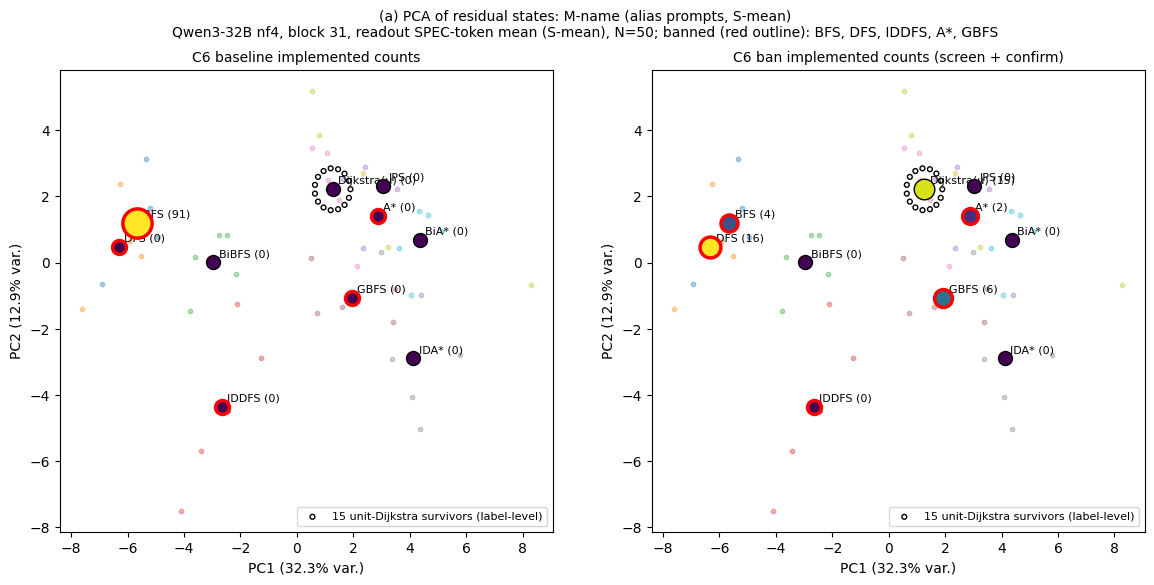

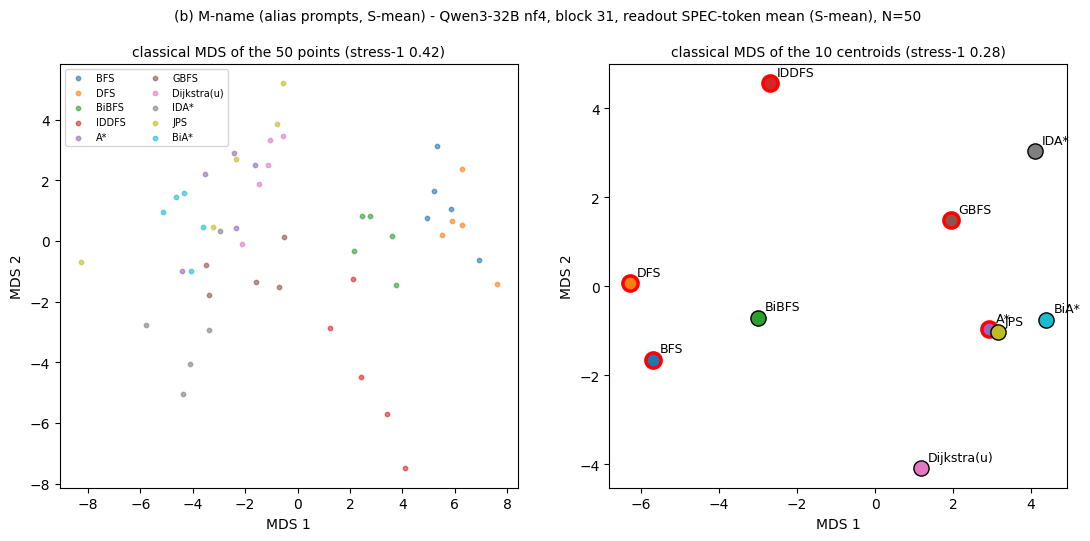

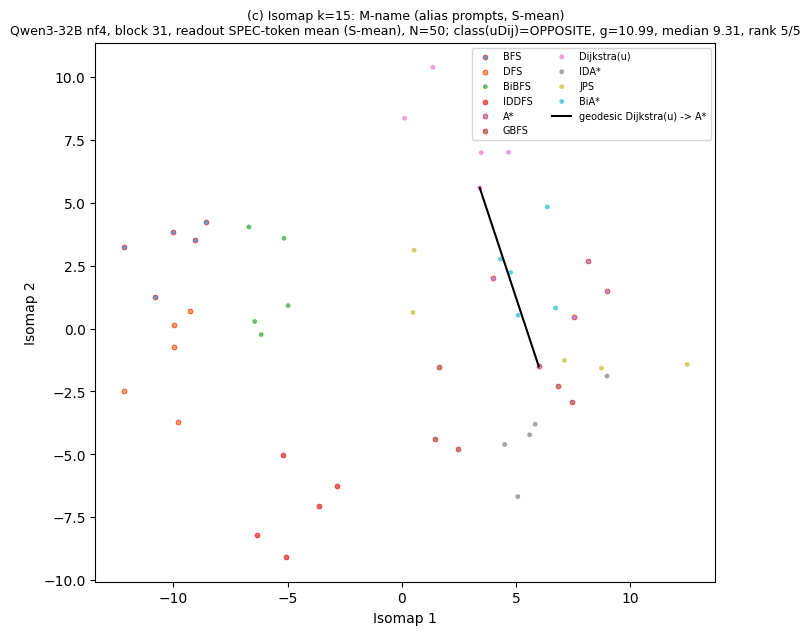

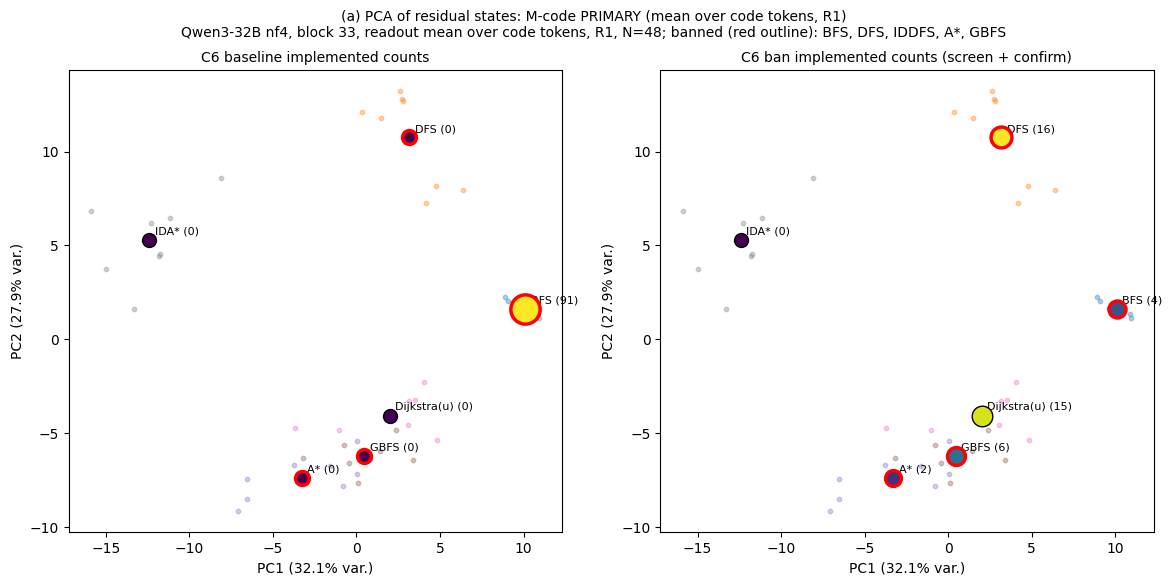

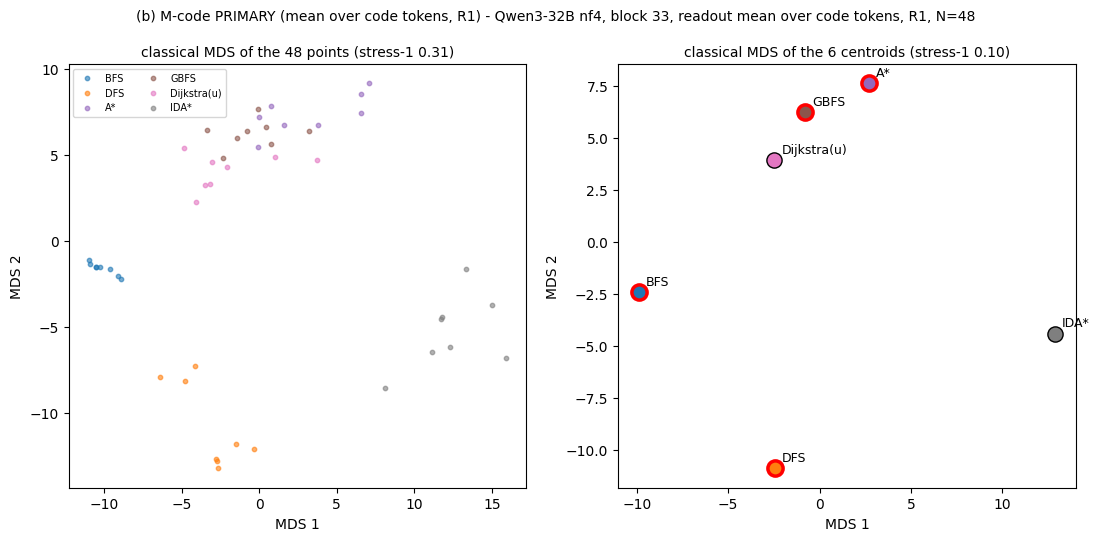

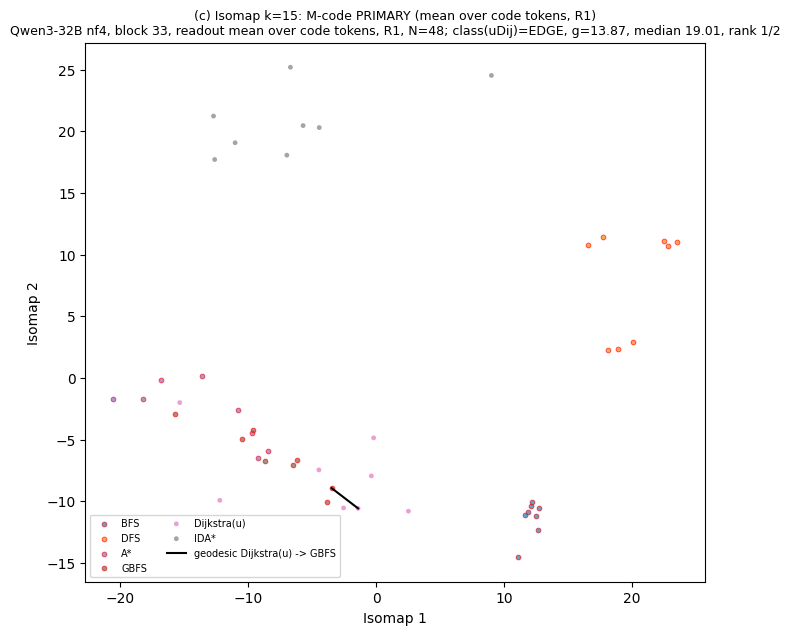

In [19]:
FIG = ROOT / "figures"
COL = dict(zip(CANON_ORDER, plt.cm.tab10(np.linspace(0, 1, 10))))
TITLES = {"mname": "M-name (alias prompts, S-mean)", "mdesc": "M-desc (name-free descriptions, S-mean)",
          "mlex": "M-lex (alias minus neutral twin, S-mean delta)",
          "mcode_PRIMARY_R1": "M-code PRIMARY (mean over code tokens, R1)",
          "mcode_PRIMARY_R2": "M-code PRIMARY (pop-position token, R2)",
          "mcode_M32_R1": "M-code Qwen3-32B-only frame (R1)", "mcode_M8_R1": "M-code Qwen3-8B-only frame (R1)",
          "mcode_PRIMARY_R1g": "M-code PRIMARY (R1 without massive tokens)",
          "mcode_PRIMARY_R3": "M-code PRIMARY (16th code token, R3: negative control)"}


def _save(fig: Any, name: str) -> None:
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()                              # notebook: display inline
    plt.close(fig)


def counts() -> tuple[Counter, Counter]:
    # notebook: was read_jsonl(IN_E44 / "data" / "labelled_C6_{baseline,ban,confirm}.jsonl") (iteration 8's labels)
    li = data["metadata"]["landing_inputs"]
    base = Counter(li["c6_baseline_adj_labels"])
    ban = Counter(li["c6_ban_adj_labels"] + li["c6_confirm_adj_labels"])
    return base, ban


def _overlay(model_tag: str, name: str, z: Any) -> tuple[np.ndarray | None, str]:
    # notebook: the original projected the 7 ban-prompt states (cache/states/ban_32b.npz) onto the S-mean manifolds and
    # the 15 unit-Dijkstra survivor programs (cache/states/mcode_32b.npz) onto M-code; neither is in the demo subset
    return None, ""


def manifold_figs(model_tag: str, name: str, geo_res: dict[str, Any]) -> None:
    f = FIG / "coords" / f"{model_tag}_{name}.npz"
    if not f.exists():
        return
    z = np.load(f, allow_pickle=False)
    labels = z["labels"]
    L = int(z["block"])
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    base, ban = counts()
    cfg = MODELS[model_tag]
    prec = "nf4" if model_tag == "32b" else "bf16"
    mdl = "Qwen3-32B" if model_tag == "32b" else "Qwen3-8B"
    readout = "SPEC-token mean (S-mean)" if not name.startswith("mcode") else TITLES[name].split("(")[-1].rstrip(")")
    cap = f"{mdl} {prec}, block {L}, readout {readout}, N={len(labels)}"
    P = z["pca2"]
    evr = z["evr"]
    Q, qlab = _overlay(model_tag, name, z)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, (cnt, ttl) in zip(axes, ((base, "C6 baseline implemented counts"), (ban, "C6 ban implemented counts "
                                                                                    "(screen + confirm)"))):
        for a in present:
            s = labels == a
            ax.scatter(P[s, 0], P[s, 1], s=10, color=COL[a], alpha=0.35)
        vmax = max(1, max(cnt.get(a, 0) for a in present))
        for a in present:
            c = P[labels == a].mean(0)
            n = cnt.get(a, 0)
            ax.scatter([c[0]], [c[1]], s=60 + 40 * np.sqrt(n + 1), c=[[n / vmax]], cmap="viridis", vmin=0, vmax=1,
                       edgecolors="red" if a in B5 else "black", linewidths=2.5 if a in B5 else 1.0, zorder=5)
            ax.annotate(f"{SHORT[a]} ({n})", c, fontsize=8, xytext=(4, 4), textcoords="offset points")
        if Q is not None:
            mk = "*" if not name.startswith("mcode") else "x"
            ax.scatter(Q[:, 0], Q[:, 1], marker=mk, s=110 if mk == "*" else 45, color="black", label=qlab, zorder=6)
            ax.legend(loc="best", fontsize=8)
        elif not name.startswith("mcode"):
            c = P[labels == UDIJ].mean(0) if UDIJ in present else None
            if c is not None:
                th = np.linspace(0, 2 * np.pi, 15, endpoint=False)
                r = 0.04 * (P.max() - P.min())
                ax.scatter(c[0] + r * np.cos(th), c[1] + r * np.sin(th), s=12, marker="o", facecolors="none",
                           edgecolors="black", label="15 unit-Dijkstra survivors (label-level)")
                ax.legend(loc="best", fontsize=8)
        ax.set_xlabel(f"PC1 ({100 * evr[0]:.1f}% var.)")
        ax.set_ylabel(f"PC2 ({100 * evr[1]:.1f}% var.)")
        ax.set_title(ttl, fontsize=10)
    fig.suptitle(f"(a) PCA of residual states: {TITLES[name]}\n{cap}; banned (red outline): "
                 f"{', '.join(SHORT[b] for b in B5)}", fontsize=10)
    _save(fig, f"pca_{model_tag}_{name}")
    # (b) MDS
    d = geo_res["L_star"]["describe"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    Ym = z["mds"]
    for a in present:
        s = labels == a
        axes[0].scatter(Ym[s, 0], Ym[s, 1], s=10, color=COL[a], label=SHORT[a], alpha=0.6)
    axes[0].legend(fontsize=7, ncol=2)
    axes[0].set_title(f"classical MDS of the {len(labels)} points (stress-1 {d['mds_points_stress1']:.2f})", fontsize=10)
    Yc = z["mds_c"]
    for i, a in enumerate(present):
        axes[1].scatter([Yc[i, 0]], [Yc[i, 1]], s=120, color=COL[a], edgecolors="red" if a in B5 else "black",
                        linewidths=2.5 if a in B5 else 1)
        axes[1].annotate(SHORT[a], Yc[i], fontsize=9, xytext=(5, 5), textcoords="offset points")
    axes[1].set_title(f"classical MDS of the {len(present)} centroids (stress-1 {d['mds_centroids_stress1']:.2f})",
                      fontsize=10)
    for ax in axes:
        ax.set_xlabel("MDS 1")
        ax.set_ylabel("MDS 2")
    fig.suptitle(f"(b) {TITLES[name]} - {cap}", fontsize=10)
    _save(fig, f"mds_{model_tag}_{name}")
    # (c) Isomap with geodesic path uDij -> nearest banned
    Y = z["iso"]
    if len(Y):
        geo = z["geo"]
        fig, ax = plt.subplots(figsize=(8, 7))
        for a in present:
            s = labels == a
            ax.scatter(Y[s, 0], Y[s, 1], s=12, color=COL[a], label=SHORT[a], alpha=0.7,
                       edgecolors="red" if a in B5 else "none", linewidths=0.6)
        kd = d[f"k{K_VERDICT}"]
        if UDIJ in present:
            nb = kd["nearest_banned"][UDIJ]
            iu = np.where(labels == UDIJ)[0]
            ib = np.where(labels == nb)[0]
            sub = geo[np.ix_(iu, ib)]
            i, j = np.unravel_index(np.argmin(sub), sub.shape)
            X = np.load(STATES_DIR / f"geo_{model_tag}_{name}_k{K_VERDICT}.npz")
            G = X["adjacency"]
            _, pred = shortest_path(G, method="D", directed=False, indices=[iu[i]], return_predecessors=True)
            path, cur = [], ib[j]
            while cur >= 0 and cur != iu[i]:
                path.append(cur)
                cur = pred[0, cur]
            path.append(iu[i])
            ax.plot(Y[path, 0], Y[path, 1], "k-", lw=1.5, label=f"geodesic {SHORT[UDIJ]} -> {SHORT[nb]}")
            ttl = (f"class(uDij)={kd['classes'][UDIJ]}, g={kd['g'][UDIJ]:.2f}, median {kd['median']:.2f}, "
                   f"rank {kd['udij_rank']}/{len(kd['g'])}")
        else:
            ttl = "unit Dijkstra not in this manifold"
        ax.legend(fontsize=7, ncol=2)
        ax.set_xlabel("Isomap 1")
        ax.set_ylabel("Isomap 2")
        ax.set_title(f"(c) Isomap k={K_VERDICT}: {TITLES[name]}\n{cap}; {ttl}", fontsize=9)
        _save(fig, f"isomap_{model_tag}_{name}")
    _ = cfg


for key, r in geo_results.items():
    if r is None:
        continue
    m, name = key.split("|")
    manifold_figs(m, name, r)

## Class table, RDM heatmaps, behavioural map and alias-level scatter (`stage_figures.py`)

* **Class table:** EDGE (blue) / MIDDLE / OPPOSITE (red) of every non-banned algorithm at k 15. Each cell shows the
  class and g/median.
* **RDMs:** the behavioural, lexical and AST-surface model RDMs beside the neural class-geodesic RDMs of this run,
  with their RSA rho in the titles.
* **Behavioural map:** classical MDS of the behavioural distance between the reference programs. These are
  behavioural coordinates, not activations.
* **Alias-level scatter (M-name):** g_alias against L1 at k 10 and k 15, the picture behind P4.

**notebook:** these functions read `rsa.json`, `lexical_regression.json`, `geometry_all.json` and the model-RDM files
in the original. Here they use this run's in-memory results and the matrices stored in the data.

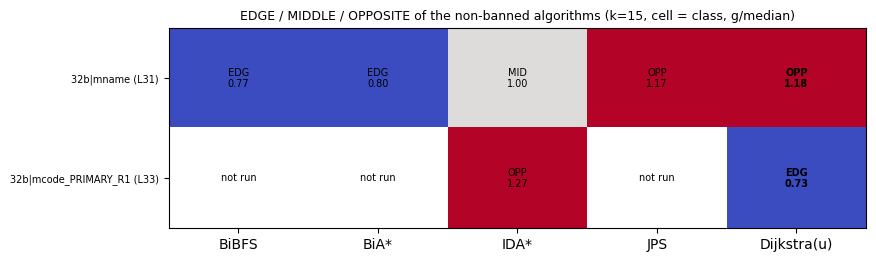

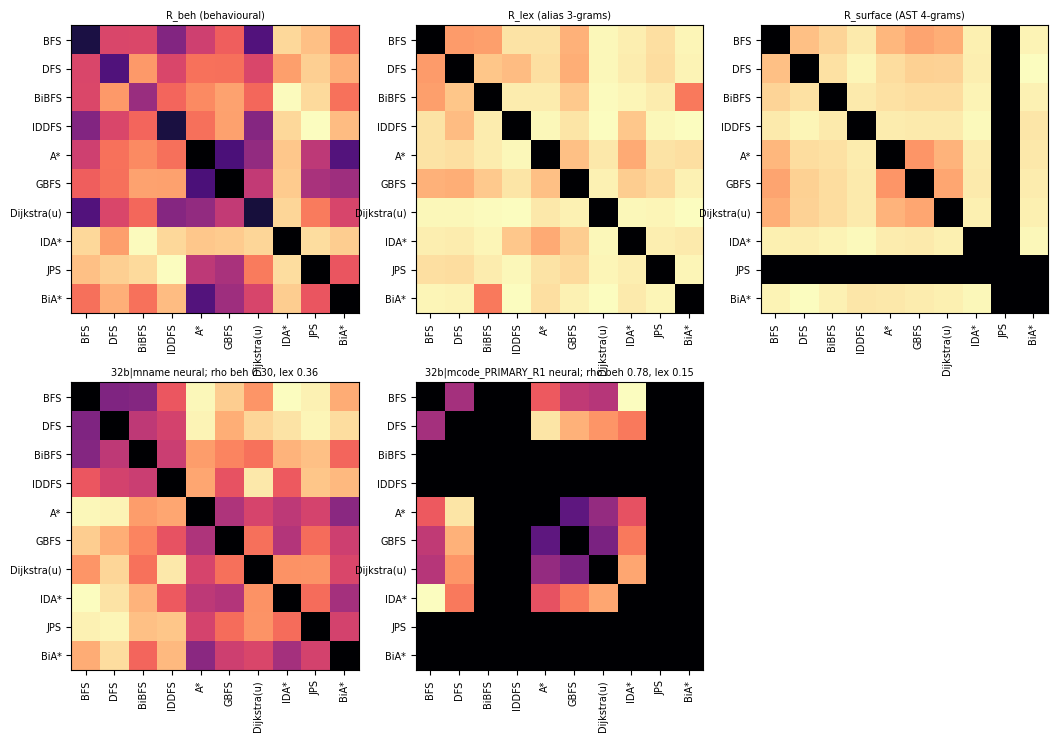

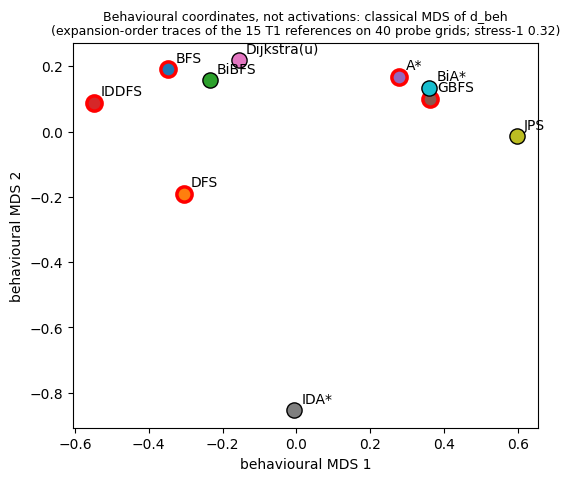

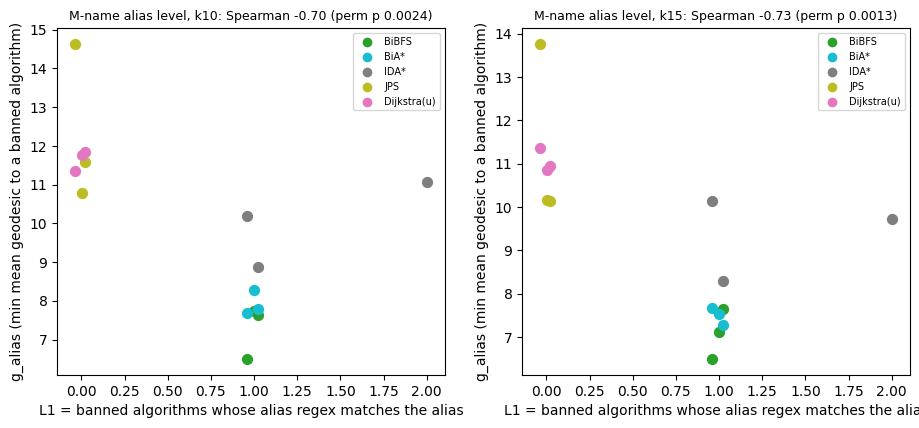

In [20]:
def class_table(geo_all: dict[str, Any]) -> None:
    rows, cells, txt = [], [], []
    cmap = {"EDGE": 0, "MIDDLE": 1, "OPPOSITE": 2}
    for key, r in geo_all.items():
        if r is None:
            continue
        kd = r["L_star"]["describe"][f"k{K_VERDICT}"]
        rows.append(f"{key} (L{r['L_star']['block']})")
        cells.append([cmap.get(kd["classes"].get(a), np.nan) for a in NB5])
        txt.append([(f"{kd['classes'][a][:3]}\n{kd['g'][a] / kd['median']:.2f}" if a in kd["classes"] else "not run")
                    for a in NB5])
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(rows) + 1.5))
    ax.imshow(np.array(cells, dtype=float), cmap="coolwarm", vmin=0, vmax=2, aspect="auto")
    for i in range(len(rows)):
        for j in range(5):
            ax.text(j, i, txt[i][j], ha="center", va="center", fontsize=7,
                    fontweight="bold" if NB5[j] == UDIJ else "normal")
    ax.set_xticks(range(5), [SHORT[a] for a in NB5])
    ax.set_yticks(range(len(rows)), rows, fontsize=7)
    ax.set_title(f"EDGE / MIDDLE / OPPOSITE of the non-banned algorithms (k={K_VERDICT}, cell = class, g/median)",
                 fontsize=9)
    _save(fig, "class_table")


def rdm_figs() -> None:
    # notebook: was read_json(RESULTS / "rsa.json"), behavioural_distance.json, lexical.json, surface_rdm.json and
    # geometry_all.json; the same objects are in memory (rs, geo_results) or in mini_demo_data.json
    rs_ = rs
    rd = data["metadata"]["model_rdms"]
    beh = data["metadata"]["behavioural"]
    mats = {"R_beh (behavioural)": np.array(rd["R_beh"]), "R_lex (alias 3-grams)": np.array(rd["R_lex"])}
    mats["R_surface (AST 4-grams)"] = np.array(rd["R_surface"])
    geo_all = geo_results
    for key in ("32b|mname", "32b|mdesc", "32b|mlex", "32b|mcode_PRIMARY_R1"):
        if key in geo_all:
            M = np.array(geo_all[key]["L_star"]["describe"][f"k{K_VERDICT}"]["class_geodesic_matrix"])
            M = (M + M.T) / 2
            np.fill_diagonal(M, 0)
            r = rs_.get(key, {}).get("models", {})
            lab = f"{key} neural; rho beh {r.get('R_beh', {}).get('rho', float('nan')):.2f}, lex " \
                  f"{r.get('R_lex', {}).get('rho', float('nan')):.2f}"
            mats[lab] = M
    n = len(mats)
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(4.2 * ((n + 1) // 2), 8.5))
    for ax, (t, M) in zip(axes.ravel(), mats.items()):
        ax.imshow(np.nan_to_num(M), cmap="magma")
        ax.set_xticks(range(10), [SHORT[a] for a in CANON_ORDER], rotation=90, fontsize=7)
        ax.set_yticks(range(10), [SHORT[a] for a in CANON_ORDER], fontsize=7)
        ax.set_title(t, fontsize=7)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    _save(fig, "rdms")
    Y = beh["behavioural_coordinates_mds"]
    fig, ax = plt.subplots(figsize=(6, 5))
    for a in CANON_ORDER:
        ax.scatter([Y[a][0]], [Y[a][1]], s=120, color=COL[a], edgecolors="red" if a in B5 else "black",
                   linewidths=2.5 if a in B5 else 1)
        ax.annotate(SHORT[a], Y[a], xytext=(5, 5), textcoords="offset points")
    ax.set_title(f"Behavioural coordinates, not activations: classical MDS of d_beh\n(expansion-order traces of the "
                 f"15 T1 references on 40 probe grids; stress-1 {beh['behavioural_mds_stress1']:.2f})", fontsize=9)
    ax.set_xlabel("behavioural MDS 1")
    ax.set_ylabel("behavioural MDS 2")
    _save(fig, "behavioural_mds")


def lexical_fig() -> None:
    r = lr.get("32b|mname")                 # notebook: was read_json(RESULTS / "lexical_regression.json")
    if not r:
        return
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, k in zip(axes, ("k10", "k15")):
        rows = r[k]["rows"]
        for row in rows:
            ax.scatter(row["L1"] + np.random.default_rng(len(row["alias"] if "alias" in row else "") + row[
                "alias_index"]).uniform(-0.08, 0.08), row["g_alias"], color=COL[row["algorithm"]], s=50)
        for a in NB5:
            ax.scatter([], [], color=COL[a], label=SHORT[a])
        ax.set_xlabel("L1 = banned algorithms whose alias regex matches the alias")
        ax.set_ylabel("g_alias (min mean geodesic to a banned algorithm)")
        ax.set_title(f"M-name alias level, {k}: Spearman {r[k]['spearman_L1']:.2f} (perm p {r[k]['perm_p_L1']:.4f})",
                     fontsize=9)
        ax.legend(fontsize=7)
    _save(fig, "lexical_alias_level_32b")


class_table(geo_results)
rdm_figs()
lexical_fig()

## Results: demo subset vs full run

The table puts every headline quantity of this run next to the artifact's full run (300 M-name points, 117 M-code
programs, 1,000 bootstrap resamples). The plot shows g / median of each non-banned algorithm at k 10 and k 15. Below
the dashed line at 1 is EDGE (closer to the banned five than the median non-banned algorithm); above it is OPPOSITE.
Filled markers are this run, hollow markers the full run. Unit Dijkstra is drawn larger.

How to read it, with the default configuration:

* On **M-name** (prompts that *name* each algorithm), unit Dijkstra sits above the median at every k, so it is
  OPPOSITE. At k 15 it is the farthest of the five non-banned algorithms from the banned five (rank 5 of 5).
* On **M-code** (name-scrubbed programs), it is the closer of the two non-banned algorithms, so it is at the EDGE.
  Its nearest banned neighbour is GBFS, another priority-queue search.
* RSA agrees. M-name follows the lexical RDM more than the behavioural one. M-code follows the behavioural and
  AST-surface RDMs and not the lexical one.
* The pre-registered rule therefore names the outcome MIXED. Where the survivor lands depends on whether the map is
  built from names or from mechanisms.

**Where the demo differs from the full run.** The subset is 2.4 times (M-code) to 6 times (M-name) smaller, so
effect sizes move:

* M-name's g/median is 1.18 here, against 1.63 in the full run.
* RSA rhos change. M-name's R_beh reaches p 0.025 here but only 0.091 in the full run, and its non-significant
  R_surface flips sign.
* Leave-one-out placement accuracy is 0.75, against 0.85.

Every class, landing verdict, bootstrap P(EDGE), P4 result and the named outcome match the full run.

                                           M-name demo     M-name full     M-code demo     M-code full
points                                              50             300              48             117
block L*                                            31              31              33              33
Dijkstra(u) class k10                         OPPOSITE        OPPOSITE            EDGE            EDGE
Dijkstra(u) class k15                         OPPOSITE        OPPOSITE            EDGE            EDGE
Dijkstra(u) rank k15 (1 = nearest)                 5/5             5/5             1/2             1/2
Dijkstra(u) g/median k15                          1.18            1.63            0.73            0.67
nearest banned k15                                  A*              A*            GBFS            GBFS
landing verdict k15 (15 survivors)            OPPOSITE        OPPOSITE            EDGE            EDGE
bootstrap P(EDGE) k15                             0.00            0.00   

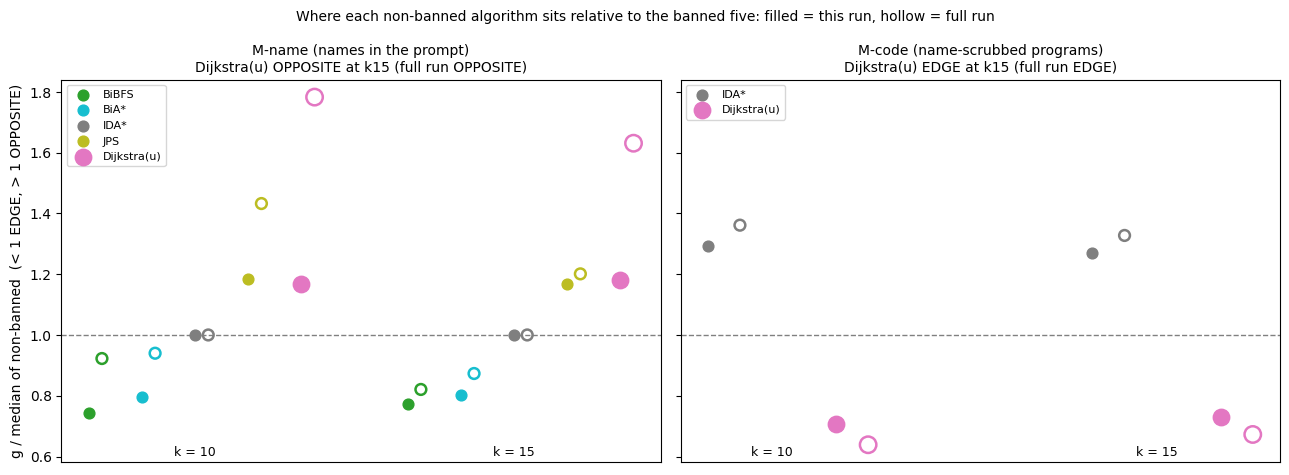

In [21]:
def _row(label: str, vals: list[Any]) -> str:
    return f"{label:<38}" + "".join(f"{str(v):>16}" for v in vals)


_keys = ["32b|mname", "32b|mcode_PRIMARY_R1"]
print(_row("", ["M-name demo", "M-name full", "M-code demo", "M-code full"]))
_lines = {}
for key in _keys:
    d, ref = geo_results[key]["L_star"]["describe"], REF[key]
    bs = geo_results[key]["L_star"]["bootstrap"][f"k{K_VERDICT}"]
    _lines.setdefault("points", []).extend([d["n_points"], ref["n_points"]])
    _lines.setdefault("block L*", []).extend([geo_results[key]["L_star"]["block"], ref["L_star"]])
    _lines.setdefault("Dijkstra(u) class k10", []).extend([d["k10"]["classes"][UDIJ], ref["k10"]["classes"][UDIJ]])
    _lines.setdefault("Dijkstra(u) class k15", []).extend([d["k15"]["classes"][UDIJ], ref["k15"]["classes"][UDIJ]])
    _lines.setdefault("Dijkstra(u) rank k15 (1 = nearest)", []).extend(
        [f"{d['k15']['udij_rank']}/{len(d['k15']['g'])}", f"{ref['k15']['udij_rank']}/{len(ref['k15']['g'])}"])
    _lines.setdefault("Dijkstra(u) g/median k15", []).extend([f"{d['k15']['udij_ratio']:.2f}",
                                                             f"{ref['k15']['udij_ratio']:.2f}"])
    _lines.setdefault("nearest banned k15", []).extend([SHORT[d["k15"]["nearest_banned"][UDIJ]],
                                                       SHORT[ref["k15"]["nearest_banned"][UDIJ]]])
    _lines.setdefault("landing verdict k15 (15 survivors)", []).extend(
        [geo_results[key]["L_star"]["landing"]["k15"]["pooled"]["verdict"], ref["k15"]["landing_pooled"]["verdict"]])
    _lines.setdefault("bootstrap P(EDGE) k15", []).extend([f"{bs['edge_probability'][UDIJ]:.2f}",
                                                          f"{ref['bootstrap_k15']['edge_probability'][UDIJ]:.2f}"])
    _lines.setdefault("bootstrap resamples", []).extend([bs["n_boot"], ref["bootstrap_k15"]["n_boot"]])
    _lines.setdefault("split-half Spearman-Brown k15", []).extend(
        [f"{geo_results[key]['L_star']['split_half']['k15']['spearman_brown']:.2f}",
         f"{ref['split_half_k15']['spearman_brown']:.2f}"])
    for mn in ("R_lex", "R_beh", "R_surface"):
        _lines.setdefault(f"RSA rho {mn} (exact p)", []).extend(
            [f"{rs[key]['models'][mn]['rho']:+.2f} ({rs[key]['models'][mn]['p_exact']:.3f})",
             f"{REF['rsa'][key][mn]['rho']:+.2f} ({REF['rsa'][key][mn]['p_exact']:.3f})"])
for label, vals in _lines.items():
    print(_row(label, vals))
_lx, _lxr = lr["32b|mname"]["k15"], REF["lexical_regression_32b|mname"]["k15"]
print(_row("Spearman(g_alias, L1) k15", [f"{_lx['spearman_L1']:+.2f}", f"{_lxr['spearman_L1']:+.2f}", "-", "-"]))
_pp, _ppr = pl["32b|mcode_PRIMARY_R1"], REF["placement_32b|mcode_PRIMARY_R1"]
print(_row("LOO placement accuracy (G-place)", ["-", "-", f"{_pp['G_place']['loo_accuracy']:.2f}",
                                                f"{_ppr['G_place']['loo_accuracy']:.2f}"]))
print(f"\nNamed outcome: {n4['named_outcome']} (full run: {REF['named_outcome']}).  Total notebook time so far: "
      f"{time.time() - _T_START:.0f} s")

# g / median of every non-banned algorithm: this run (filled) vs the full run (hollow)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, key, ttl in zip(axes, _keys, ("M-name (names in the prompt)", "M-code (name-scrubbed programs)")):
    d, ref = geo_results[key]["L_star"]["describe"], REF[key]
    algs = d["nonbanned_used"]
    for xi, k in enumerate((K_SECOND, K_VERDICT)):
        for j, a in enumerate(algs):
            x = xi * (len(algs) + 1) + j
            big = 140 if a == UDIJ else 60
            ax.scatter([x], [d[f"k{k}"]["g"][a] / d[f"k{k}"]["median"]], s=big, color=COL[a], zorder=3,
                       label=SHORT[a] if xi == 0 else None)
            ax.scatter([x + 0.25], [ref[f"k{k}"]["g"][a] / ref[f"k{k}"]["median"]], s=big, facecolors="none",
                       edgecolors=COL[a], linewidths=1.8, zorder=3)
        ax.text(xi * (len(algs) + 1) + (len(algs) - 1) / 2, 0.01, f"k = {k}",
                ha="center", va="bottom", fontsize=9, transform=ax.get_xaxis_transform())
    ax.axhline(1.0, ls="--", color="grey", lw=1)
    ax.set_xticks([])
    ax.set_title(f"{ttl}\nDijkstra(u) {d['k15']['classes'][UDIJ]} at k15 (full run {ref['k15']['classes'][UDIJ]})",
                 fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("g / median of non-banned  (< 1 EDGE, > 1 OPPOSITE)")
fig.suptitle("Where each non-banned algorithm sits relative to the banned five: filled = this run, hollow = full run",
             fontsize=10)
plt.tight_layout()
fig.savefig(FIG / "summary_g_ratio.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)